# Parte 2 — Experimentos no Wiki-RfA

Experimentos de BFS, Dijkstra, DFS e Bellman-Ford, com responsabilidades e revisão registradas na documentação da equipe.

Este notebook lê o CSV tratado produzido por preparacao_dataset_wikiRfA.ipynb. Execute as células em ordem, em uma sessão nova. Não é necessário executar o notebook de tratamento novamente se o CSV já estiver disponível.

**Pergunta de pesquisa:** Como a transformação dos pesos negativos para permitir o uso de Dijkstra altera os caminhos mínimos e a interpretação dos custos no grafo Wiki-RfA?

Este notebook reúne os experimentos de BFS, Dijkstra, DFS e Bellman-Ford e, nas seções 12 a 15, a preparação do benchmark de BFS e Dijkstra. As seções 16 e 17 conferem e consolidam os casos e as medições já salvas, selecionando o benchmark de BFS/Dijkstra realizado na máquina de André. O conjunto atual possui 34 configurações e 170 tempos.

**Apoio de IA:** ChatGPT (Codex) auxiliou na organização deste notebook e no código de chamada e exportação. O BFS utilizado é a implementação existente do projeto. As células foram criadas sem execução.


## 1. Preparação

Localiza a raiz procurando as pastas src e data no diretório atual e em seus ancestrais. Permite iniciar o notebook pela raiz ou pela pasta do dataset, sem depender das variáveis de outro notebook.


In [113]:
# [IA] ChatGPT (Codex) – localizar o projeto e importar as funções existentes
import json
import math
import sys
from pathlib import Path

raiz_projeto = Path.cwd().resolve()
while not ((raiz_projeto / "src").is_dir() and (raiz_projeto / "data").is_dir()):
    if raiz_projeto == raiz_projeto.parent:
        raise FileNotFoundError("Abra o notebook dentro da pasta do projeto.")
    raiz_projeto = raiz_projeto.parent

if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

from src.graphs.io import carregar_dataset
from src.graphs.algorithms import bfs

print("Raiz do projeto:", raiz_projeto)


Raiz do projeto: C:\Users\brend\OneDrive\Documentos\projeto-grafos-g1\projeto-grafos-g1


## 2. Carregamento do grafo

Lê o CSV tratado com a coluna PESO. Preserva direção, laços e arcos paralelos, sem reaplicar o incremento nem alterar o arquivo. BFS ignora os valores dos pesos.


In [114]:
# [IA] ChatGPT (Codex) – carregar o CSV tratado para os experimentos
arquivo_tratado = raiz_projeto / "data" / "dataset_parte2" / "processed" / "wikiRfA_tratado.csv"
grafo_dataset = carregar_dataset(arquivo_tratado, coluna_peso="PESO")
print("Vértices:", len(grafo_dataset))


Vértices: 11376


## 3. BFS em três fontes

Fontes selecionadas a partir dos graus de saída salvos nas métricas: Siva1979 (grau 1.232), 'sed (grau 3, próximo da mediana dos graus positivos) e !---slappdash---! (grau 1). Empates foram resolvidos pelo nome, em ordem lexicográfica do Python, mantendo os identificadores originais.

A quantidade de outros usuários alcançados exclui a própria fonte. A maior distância considera apenas distâncias finitas, incluindo a distância zero da fonte. Para usuários inalcançáveis, a distância é registrada como null no JSON. Predecessor null pode indicar a fonte ou um usuário inalcançável; consulte também a distância.



In [115]:
# [IA] ChatGPT (Codex) – chamar o BFS existente e organizar seus resultados
fontes = ["Siva1979", "'sed", "!---slappdash---!"]
for fonte in fontes:
    if fonte not in grafo_dataset:
        raise ValueError(f"Fonte não encontrada no grafo: {fonte}")

resultados_bfs = []
for fonte in fontes:
    distancias, predecessores = bfs(grafo_dataset, fonte)
    distancias_json = {}
    outros_alcancados = 0
    maior_distancia = 0

    for usuario, distancia in distancias.items():
        if distancia == math.inf:
            distancias_json[usuario] = None
        else:
            distancias_json[usuario] = distancia
            if usuario != fonte:
                outros_alcancados += 1
            if distancia > maior_distancia:
                maior_distancia = distancia

    resultados_bfs.append({
        "fonte": fonte,
        "grau_saida_fonte": len(grafo_dataset[fonte]),
        "outros_usuarios_alcancados": outros_alcancados,
        "maior_distancia_finita": maior_distancia,
        "distancias": distancias_json,
        "predecessores": predecessores,
    })
    print(f"{fonte}: {outros_alcancados} outros usuários alcançados; maior distância = {maior_distancia} arcos.")


Siva1979: 3443 outros usuários alcançados; maior distância = 5 arcos.
'sed: 3444 outros usuários alcançados; maior distância = 6 arcos.
!---slappdash---!: 3444 outros usuários alcançados; maior distância = 7 arcos.


## 4. Exportação dos resultados

Salva os resultados em out/parte2/bfs_fontes.json, identificando a entrada e a unidade das distâncias. Executar novamente sobrescreve apenas esse arquivo. Não altera o CSV ou o JSON das métricas. Este arquivo não substitui o relatório de benchmark parte2_report.json.


In [116]:
# [IA] ChatGPT (Codex) – exportar os resultados das três fontes em JSON
relatorio_bfs = {
    "algoritmo": "BFS",
    "arquivo_entrada": arquivo_tratado.relative_to(raiz_projeto).as_posix(),
    "coluna_peso_carregada": "PESO",
    "pesos_considerados_na_busca": False,
    "unidade_distancia": "arcos",
    "vertices": len(grafo_dataset),
    "resultados": resultados_bfs,
}
pasta_saida = raiz_projeto / "out" / "parte2"
pasta_saida.mkdir(parents=True, exist_ok=True)
arquivo_bfs = pasta_saida / "bfs_fontes.json"
with open(arquivo_bfs, "w", encoding="utf-8") as arquivo:
    json.dump(relatorio_bfs, arquivo, ensure_ascii=False, indent=2, allow_nan=False)

print("Resultados salvos em:", arquivo_bfs)


Resultados salvos em: C:\Users\brend\OneDrive\Documentos\projeto-grafos-g1\projeto-grafos-g1\out\parte2\bfs_fontes.json


## 5. Transformação dos pesos para Dijkstra

Transformação aprovada pela equipe: novo peso = PESO + 1. O menor PESO conferido no CSV foi -1; por isso, o deslocamento de 1 torna os pesos não negativos. A versão transformada fica em grafo_dijkstra, sem modificar grafo_dataset nem o CSV. Direção, ordem dos arcos, laços e arcos paralelos são preservados.

Para um caminho com k arcos, o custo transformado é o custo em PESO mais k. Portanto, esta transformação pode mudar os caminhos mínimos e não deve ser apresentada como preservação dos custos ou dos caminhos originais. PESO já inclui o incremento por repetição e não é a coluna VOTE original.

Esta célula apenas prepara e confere o grafo transformado. Não executa Dijkstra nem salva arquivos.

### Justificativa da transformação

Escolhemos somar 1 ao peso de todos os arcos porque Dijkstra exige pesos não negativos. Com pesos negativos, a justificativa de que uma distância pode ser considerada definitiva deixa de valer. Como o menor PESO encontrado foi −1, somar 1 produz um peso mínimo de zero. Esse é o menor deslocamento constante que elimina os pesos negativos.

A transformação preservou os vértices, os arcos — incluindo paralelos e laços — e suas direções. Também preservou a ordem relativa dos pesos individuais: um arco mais barato continua mais barato que outro. Os pesos anteriores foram mantidos em um grafo separado.

Entretanto, somar 1 a cada arco não afeta todos os caminhos igualmente. Um caminho com mais arcos recebe um acréscimo maior que um caminho com menos arcos, podendo mudar qual caminho tem o menor custo.

Esse comportamento se conecta à nossa pergunta de pesquisa: queremos verificar em quantos pares os caminhos encontrados com os pesos anteriores e transformados coincidem e em quantos diferem. A comparação com Bellman-Ford será feita apenas quando houver um caminho mínimo finito para o destino. Se houver empate de custos, caminhos diferentes podem ser igualmente ótimos; por isso, uma diferença na sequência de vértices não comprova, sozinha, uma mudança causada pela transformação.

**Apoio de IA:** justificativa elaborada pelo grupo e aprovada após revisão de clareza e precisão conceitual por ChatGPT (Codex). O texto descreve a decisão e o plano de comparação; não apresenta resultados dessa comparação.


In [117]:
# [IA] ChatGPT (Codex) – aplicar o deslocamento de pesos aprovado pela equipe em um grafo separado
deslocamento_peso = 1
grafo_dijkstra = {}
arcos_originais = 0
arcos_transformados = 0

for origem, vizinhos in grafo_dataset.items():
    grafo_dijkstra[origem] = []
    arcos_originais += len(vizinhos)
    for destino, peso in vizinhos:
        novo_peso = peso + deslocamento_peso
        assert novo_peso >= 0, "O deslocamento não eliminou todos os pesos negativos."
        grafo_dijkstra[origem].append((destino, novo_peso))
        arcos_transformados += 1

assert len(grafo_dijkstra) == len(grafo_dataset)
assert arcos_transformados == arcos_originais
print("Transformação: novo peso = PESO +", deslocamento_peso)
print("Vértices preservados:", len(grafo_dijkstra))
print("Arcos preservados:", arcos_transformados)
print("Todos os pesos transformados são não negativos.")


Transformação: novo peso = PESO + 1
Vértices preservados: 11376
Arcos preservados: 196614
Todos os pesos transformados são não negativos.


## 6. Dijkstra em cinco pares

Executar após a transformação da seção 5. Os pares foram selecionados a partir dos resultados de BFS, usando as três fontes e destinos nos níveis 1, 5, 2, 6 e 7, respectivamente. Para cada nível escolhido, foi usado o primeiro destino em ordem lexicográfica do Python.

O Dijkstra existente será executado uma vez por origem; os resultados serão consultados para os cinco pares. Os caminhos minimizam a soma de PESO + 1 e podem diferir dos caminhos BFS. O custo registrado refere-se exclusivamente aos pesos transformados, não ao custo mínimo em PESO nem aos votos originais.

Os caminhos registram a sequência de vértices. Havendo arcos paralelos, essa sequência não identifica individualmente cada ocorrência; o custo transformado vem das distâncias devolvidas pelo algoritmo. Não há medição de tempo nesta etapa.


In [118]:
# [IA] ChatGPT (Codex) – chamar Dijkstra e a reconstrução existentes para os cinco pares aprovados
from src.graphs.algorithms import dijkstra, reconstruir_caminho

pares_dijkstra = [
    ("Siva1979", "(aeropagitica)"),
    ("Siva1979", "Dieter Simon"),
    ("'sed", "9cds"),
    ("'sed", "Caltrop"),
    ("!---slappdash---!", "Caltrop"),
]

for origem, destino in pares_dijkstra:
    if origem not in grafo_dijkstra or destino not in grafo_dijkstra:
        raise ValueError(f"Origem ou destino fora do grafo: {origem} -> {destino}")

buscas_dijkstra = {}
resultados_dijkstra = []
for origem, destino in pares_dijkstra:
    if origem not in buscas_dijkstra:
        buscas_dijkstra[origem] = dijkstra(grafo_dijkstra, origem)
    distancias, predecessores = buscas_dijkstra[origem]

    if distancias[destino] == math.inf:
        status = "SEM_CAMINHO"
        caminho = []
        custo = None
        quantidade_arcos = None
    else:
        status = "OK"
        caminho = reconstruir_caminho(distancias, predecessores, destino)
        custo = distancias[destino]
        quantidade_arcos = len(caminho) - 1

    resultados_dijkstra.append({
        "origem": origem,
        "destino": destino,
        "status": status,
        "caminho": caminho,
        "quantidade_arcos": quantidade_arcos,
        "custo_transformado": custo,
    })
    print(f"{origem} -> {destino}: {status}; custo transformado = {custo}; arcos = {quantidade_arcos}")


Siva1979 -> (aeropagitica): OK; custo transformado = 0; arcos = 3
Siva1979 -> Dieter Simon: OK; custo transformado = 6; arcos = 5
'sed -> 9cds: OK; custo transformado = 2; arcos = 2
'sed -> Caltrop: OK; custo transformado = 8; arcos = 7
!---slappdash---! -> Caltrop: OK; custo transformado = 8; arcos = 8


## 7. Exportação dos cinco pares

Salva out/parte2/dijkstra_pares.json, identificando a transformação e os resultados dos cinco pares. Executar novamente sobrescreve esse arquivo. Não modifica o CSV, os grafos, as métricas ou o resultado BFS. Não substitui o relatório de benchmark.


In [119]:
# [IA] ChatGPT (Codex) – exportar caminhos e custos transformados dos cinco pares
relatorio_dijkstra = {
    "algoritmo": "DIJKSTRA",
    "arquivo_entrada": arquivo_tratado.relative_to(raiz_projeto).as_posix(),
    "coluna_peso_base": "PESO",
    "transformacao": "novo_peso = PESO + deslocamento",
    "deslocamento": deslocamento_peso,
    "vertices": len(grafo_dijkstra),
    "buscas_por_origem": len(buscas_dijkstra),
    "resultados": resultados_dijkstra,
}
pasta_saida = raiz_projeto / "out" / "parte2"
pasta_saida.mkdir(parents=True, exist_ok=True)
arquivo_dijkstra = pasta_saida / "dijkstra_pares.json"
with open(arquivo_dijkstra, "w", encoding="utf-8") as arquivo:
    json.dump(relatorio_dijkstra, arquivo, ensure_ascii=False, indent=2, allow_nan=False)

print("Resultados salvos em:", arquivo_dijkstra)


Resultados salvos em: C:\Users\brend\OneDrive\Documentos\projeto-grafos-g1\projeto-grafos-g1\out\parte2\dijkstra_pares.json


## 8. DFS em três fontes — André

Executar após a preparação e o carregamento do grafo (seções 1 e 2). Reutiliza as três fontes já registradas no BFS: `Siva1979`, `'sed` e `!---slappdash---!`. Usa o grafo com PESO, sem transformação adicional; o DFS ignora os pesos e preserva a ordem dos vizinhos do carregador. A busca fica restrita à fonte escolhida, com `cobrir_todos=False`.

São registrados ordem de descoberta, tempos, predecessores, contagens de classificação e indicação de ciclos. Os tempos são contadores de eventos da DFS, não medições de desempenho. Não são calculados caminhos mínimos nem camadas de distância nesta seção. A classificação exportada é uma contagem por tipo; os registros individuais de cada arco não são exportados.

**Apoio de IA:** ChatGPT (Codex) auxiliou nas chamadas da função existente, exportação e conferências técnicas. André deve conferir os resultados e elaborar a interpretação autoral. O código do algoritmo não foi alterado nesta etapa.


In [120]:
# [IA] ChatGPT (Codex) – chamar o DFS existente em três fontes e organizar os retornos
from src.graphs.algorithms import dfs

# Reutiliza as fontes já registradas nos experimentos BFS; André deve confirmar essa seleção.
fontes_dfs = ["Siva1979", "'sed", "!---slappdash---!"]
resultados_dfs = []
for fonte in fontes_dfs:
    if fonte not in grafo_dataset:
        raise ValueError(f"Fonte não encontrada no grafo: {fonte}")
    descoberta, termino, predecessores, classificacao, tem_ciclo = dfs(
        grafo_dataset, fonte, cobrir_todos=False
    )
    contagens = {tipo: 0 for tipo in ("arvore", "retorno", "avanco", "cruzamento")}
    for tipo in classificacao.values():
        contagens[tipo] += 1

    # Conferência dos retornos e da preservação de cada ocorrência de arco.
    assert set(descoberta) == set(termino) == set(predecessores)
    assert predecessores[fonte] is None
    assert all(descoberta[v] < termino[v] for v in descoberta)
    assert len(classificacao) == sum(len(grafo_dataset[v]) for v in descoberta)
    assert contagens["arvore"] == len(descoberta) - 1
    assert tem_ciclo == (contagens["retorno"] > 0)
    assert all(destino in descoberta for origem in descoberta for destino, _ in grafo_dataset[origem])

    resultados_dfs.append({
        "fonte": fonte,
        "vertices_alcancados_incluindo_fonte": len(descoberta),
        "outros_usuarios_alcancados": len(descoberta) - 1,
        "ordem_descoberta": list(descoberta),
        "tempos_descoberta": descoberta,
        "tempos_termino": termino,
        "predecessores": predecessores,
        "arcos_classificados": len(classificacao),
        "classificacao_arcos": contagens,
        "tem_ciclo": tem_ciclo,
    })
    print(f"{fonte}: {len(descoberta)} vértices; {len(classificacao)} arcos classificados; ciclo = {tem_ciclo}.")


Siva1979: 3444 vértices; 125455 arcos classificados; ciclo = True.
'sed: 3445 vértices; 125458 arcos classificados; ciclo = True.
!---slappdash---!: 3445 vértices; 125456 arcos classificados; ciclo = True.


## 9. Exportação do DFS

Salva `out/parte2/dfs_fontes.json`. Executar novamente sobrescreve apenas esse arquivo. Não modifica CSV, métricas ou resultados de BFS e Dijkstra. A saída não substitui o benchmark `parte2_report.json` nem a análise autoral no PDF.


In [121]:
# [IA] ChatGPT (Codex) – exportar os retornos do DFS existente, sem interpretação dos resultados
relatorio_dfs = {
    "algoritmo": "DFS",
    "arquivo_entrada": arquivo_tratado.relative_to(raiz_projeto).as_posix(),
    "coluna_peso_carregada": "PESO",
    "pesos_considerados_na_busca": False,
    "cobrir_todos": False,
    "ordem_vizinhos": "ordem dos arcos no CSV tratado, preservada pelo carregador",
    "identidade_arco": "(origem, destino, indice_na_adjacencia), com indice iniciando em zero",
    "vertices": len(grafo_dataset),
    "resultados": resultados_dfs,
}
pasta_saida_dfs = raiz_projeto / "out" / "parte2"
pasta_saida_dfs.mkdir(parents=True, exist_ok=True)
arquivo_dfs = pasta_saida_dfs / "dfs_fontes.json"
with open(arquivo_dfs, "w", encoding="utf-8") as saida:
    json.dump(relatorio_dfs, saida, ensure_ascii=False, indent=2, allow_nan=False)
print("Resultados DFS salvos em:", arquivo_dfs)


Resultados DFS salvos em: C:\Users\brend\OneDrive\Documentos\projeto-grafos-g1\projeto-grafos-g1\out\parte2\dfs_fontes.json


## Interpretação dos resultados do DFS 

O DFS alcançou 3.444 vértices a partir de Siva1979 e 3.445 a partir de 'sed e !---slappdash---!, incluindo cada fonte. Nenhuma delas alcançou todos os 11.376 vértices do grafo. As quantidades próximas não garantem que os conjuntos visitados sejam iguais.

As três execuções encontraram arcos de retorno, indicando ciclos dirigidos. Isso não comprova ciclos negativos, pois o DFS ignora os pesos.

A quantidade de arcos de árvore correspondeu ao número de vértices alcançados menos um. Os resultados descrevem alcançabilidade e ciclos, sem determinar caminhos ou custos mínimos.

Uso de IA: Codex me auxiliou na gramática do meu texto de análise e posteriormente sintetizou a minha frase para deixar ela mais direta e concisa.

## 10. Bellman-Ford 

Executar após a preparação e o carregamento (seções 1 e 2). Os casos abaixo são sugestões de Codex extraídas do CSV tratado.

- **Peso negativo sem ciclo negativo:** usuários `Malleus Fatuorum` e `BDD`; fonte `Malleus Fatuorum`.
- **Com ciclo negativo:** usuários `Rcsprinter123` e `Jasper Deng`; fonte `Rcsprinter123`.

Em ambos, o filtro mantém todas as linhas em que SOURCE e TARGET pertencem ao conjunto de usuários do caso: são subgrafos induzidos. Usa a coluna PESO já calculada, sem a transformação de Dijkstra e sem inventar votos ou pesos. Os números de linha identificam o CSV tratado exportado pelo projeto, com o cabeçalho na linha 1; não são índices do CSV bruto.

São exemplos mínimos para conferir os dois comportamentos. Não constituem amostras representativas da rede completa e não substituem os três tamanhos do benchmark.

As chamadas usam o Bellman-Ford existente, sem alterar sua implementação. A permissão para dispensar novos marcadores foi informada por André; o apoio de IA continua registrado neste texto e no log.


In [122]:
import csv
from src.graphs.algorithms import bellman_ford, reconstruir_caminho
from src.graphs.graph import adicionar_arco

# [IA] ChatGPT (Codex) – Sugestões de casos mínimos extraídos do CSV
casos_bellman = [
    {
        "id": "negativo_sem_ciclo",
        "usuarios": ["Malleus Fatuorum", "BDD"],
        "fonte": "Malleus Fatuorum",
        "espera_ciclo_negativo": False,
    },
    {
        "id": "ciclo_negativo",
        "usuarios": ["Rcsprinter123", "Jasper Deng"],
        "fonte": "Rcsprinter123",
        "espera_ciclo_negativo": True,
    },
]

with open(arquivo_tratado, newline="", encoding="utf-8-sig") as entrada:
    registros_bellman = list(csv.DictReader(entrada))

resultados_bellman = []
for caso in casos_bellman:
    usuarios_caso = set(caso["usuarios"])
    grafo_caso = {usuario: [] for usuario in caso["usuarios"]}
    arcos_caso = []
    # [IA] ChatGPT (Codex) – Recorte induzido: mantém todas as linhas cujos dois extremos pertencem ao par.
    # [IA] ChatGPT (Codex) – Não altera pesos, direção, laços ou ocorrências paralelas.
    for indice, registro in enumerate(registros_bellman):
        origem, destino = registro["SOURCE"], registro["TARGET"]
        if origem in usuarios_caso and destino in usuarios_caso:
            peso = int(registro["PESO"])
            indice_adjacencia = len(grafo_caso[origem])
            adicionar_arco(grafo_caso, origem, destino, peso)
            arcos_caso.append({
                "indice_registro_csv_base_zero": indice,
                "linha_csv_com_cabecalho": indice + 2,
                "origem": origem,
                "destino": destino,
                "indice_adjacencia": indice_adjacencia,
                "VOTE": int(registro["VOTE"]),
                "RESULT": int(registro["RESULT"]),
                "PESO": peso,
            })

    assert caso["fonte"] in grafo_caso
    assert any(arco["PESO"] < 0 for arco in arcos_caso)
    distancias, predecessores, ciclo = bellman_ford(grafo_caso, caso["fonte"])
    assert (ciclo is not None) == caso["espera_ciclo_negativo"]

    resultado = {
        "id": caso["id"],
        "fonte": caso["fonte"],
        "usuarios": caso["usuarios"],
        "vertices": len(grafo_caso),
        "arcos": arcos_caso,
        "tem_ciclo_negativo": ciclo is not None,
    }
    if ciclo is None:
        resultado["status"] = "OK"
        resultado["distancias"] = {
            v: None if d == math.inf else d for v, d in distancias.items()
        }
        resultado["predecessores"] = predecessores
        resultado["caminhos"] = {
            v: [] if distancias[v] == math.inf else reconstruir_caminho(distancias, predecessores, v)
            for v in grafo_caso
        }
        assert all(d != math.inf for d in distancias.values()), "Os usuários do exemplo devem ser alcançáveis."
        assert distancias["Malleus Fatuorum"] == 0
        assert distancias["BDD"] == -1
        print(caso["id"], "fonte:", caso["fonte"], "distâncias:", resultado["distancias"])
    else:
        resultado["status"] = "CICLO_NEGATIVO"
        assert ciclo[0] == ciclo[-1]
        arcos_do_ciclo = []
        for origem, destino in zip(ciclo, ciclo[1:]):
            candidatos = [a for a in arcos_caso if a["origem"] == origem and a["destino"] == destino]
            # [IA] ChatGPT (Codex) – Os exemplos propostos têm um único arco em cada direção do ciclo.
            # [IA] ChatGPT (Codex) – Se a seleção mudar e houver paralelos, não escolher uma ocorrência silenciosamente.
            if len(candidatos) != 1:
                raise ValueError("Ciclo com ocorrências paralelas: é necessário identificar o arco utilizado.")
            arcos_do_ciclo.append(candidatos[0])
        custo_ciclo = sum(a["PESO"] for a in arcos_do_ciclo)
        assert custo_ciclo < 0
        resultado["ciclo"] = ciclo
        resultado["arcos_ciclo"] = arcos_do_ciclo
        resultado["custo_ciclo"] = custo_ciclo
        resultado["distancias"] = None
        resultado["observacao_distancias"] = "Valores provisórios da execução com ciclo negativo não são apresentados como custos mínimos finitos."
        print(caso["id"], "fonte:", caso["fonte"], "ciclo:", ciclo, "custo:", custo_ciclo)
    resultados_bellman.append(resultado)


negativo_sem_ciclo fonte: Malleus Fatuorum distâncias: {'Malleus Fatuorum': 0, 'BDD': -1}
ciclo_negativo fonte: Rcsprinter123 ciclo: ['Jasper Deng', 'Rcsprinter123', 'Jasper Deng'] custo: -2


## 11. Exportação dos casos de Bellman-Ford

Salva `out/parte2/bellman_ford_casos.json`, com fontes, usuários, linhas do CSV tratado, pesos e resultados. No caso sem ciclo negativo, exporta distâncias, predecessores e caminhos. No caso com ciclo negativo, exporta a sequência, os arcos identificados e o custo do ciclo. As distâncias provisórias desse segundo caso não são exportadas como mínimos finitos.

Executar novamente sobrescreve apenas essa saída. Não modifica os dados nem os resultados dos demais algoritmos.


In [123]:
# [IA] ChatGPT (Codex) – Auxílio na lógica do código
relatorio_bellman = {
    "algoritmo": "BELLMAN_FORD",
    "arquivo_entrada": arquivo_tratado.relative_to(raiz_projeto).as_posix(),
    "sha256_entrada": __import__("hashlib").sha256(arquivo_tratado.read_bytes()).hexdigest(),
    "coluna_peso": "PESO",
    "regra_recorte": "subgrafo induzido pelos usuários informados; todas as ocorrências entre eles são preservadas",
    "selecao": "exemplos mínimos sugeridos por Codex para conferência e justificativa autoral de André",
    "benchmark": False,
    "resultados": resultados_bellman,
}
arquivo_bellman = raiz_projeto / "out" / "parte2" / "bellman_ford_casos.json"
arquivo_bellman.parent.mkdir(parents=True, exist_ok=True)
with open(arquivo_bellman, "w", encoding="utf-8") as saida:
    json.dump(relatorio_bellman, saida, ensure_ascii=False, indent=2, allow_nan=False)
print("Casos Bellman-Ford salvos em:", arquivo_bellman)


Casos Bellman-Ford salvos em: C:\Users\brend\OneDrive\Documentos\projeto-grafos-g1\projeto-grafos-g1\out\parte2\bellman_ford_casos.json


## Justificativas e interpretação dos casos de Bellman-Ford 

Foram usados dois recortes pequenos do Wiki-RfA, com o objetivo de verificar os comportamentos do Bellman-Ford com pesos negativos. Cada recorte preserva todos os arcos entre os dois usuários selecionados e seus valores de PESO, facilitando a conferência dos resultados.

No primeiro caso, com fonte em Malleus Fatuorum, há um arco até BDD com peso −1 e nenhum caminho de volta. O algoritmo retornou distância −1 até BDD e não identificou ciclo negativo. No segundo, Rcsprinter123 e Jasper Deng possuem um arco em cada direção, ambos com peso −1. A soma dos pesos do ciclo é −2, compatível com a detecção de ciclo negativo pelo algoritmo.

Os exemplos permitem conferir a diferença entre encontrar um caminho de custo negativo e detectar um ciclo negativo alcançável pela fonte. Como os recortes possuem apenas dois usuários, seus resultados não descrevem o comportamento de toda a rede nem permitem avaliar o desempenho do algoritmo em grafos maiores.

Uso de IA: Codex me auxiliou na gramática do meu texto de análise e posteriormente sintetizou a minha frase para deixar ela mais direta e concisa.


## 12. Preparação do benchmark de BFS e Dijkstra 

Estas seções dependem apenas da preparação e do carregamento das seções 1 e 2 e do arquivo src/benchmark.py atualizado. Não dependem de executar DFS ou Bellman-Ford. Os recortes são preparados antes da medição, com PESO já calculado e semente 42. As fontes são escolhidas no recorte de 10% e mantidas nos três tamanhos.

A execução abaixo apenas prepara recortes e fontes; não mede algoritmos nem salva arquivos.


In [124]:
# [IA] ChatGPT (Codex) – integrar a preparação aprovada dos recortes e fontes
from src.benchmark import criar_recortes, selecionar_fontes, medir_algoritmo
from src.graphs.algorithms import bfs, dijkstra

semente_benchmark = 42
repeticoes_benchmark = 5
deslocamento_benchmark = 1
recortes_benchmark = criar_recortes(grafo_dataset, semente=semente_benchmark)
fontes_benchmark = selecionar_fontes(recortes_benchmark)

print("Fontes do benchmark:", fontes_benchmark)
for recorte in recortes_benchmark:
    print(recorte["percentual"], "%:", recorte["vertices"], "vértices e", recorte["arcos"], "arcos")


Fontes do benchmark: ['Siva1979', 'Gwynand', 'John Carter']
10 %: 5636 vértices e 19661 arcos
50 %: 9187 vértices e 98307 arcos
100 %: 11376 vértices e 196614 arcos


## 13. Alcance das fontes fora da medição

Executa BFS em PESO e Dijkstra em PESO + 1 uma vez por fonte e tamanho, comparando os conjuntos de usuários alcançados e excluindo a própria fonte. Essas chamadas não são aquecimento nem repetições medidas. A conferência ocorre aqui, sem script ou arquivo de saída adicional.


In [125]:
# [IA] ChatGPT (Codex) – conferir alcance dos dois algoritmos fora do tempo medido
alcances_benchmark = {}
for recorte in recortes_benchmark:
    percentual = recorte["percentual"]
    grafo_transformado = {}
    for origem, vizinhos in recorte["grafo"].items():
        grafo_transformado[origem] = [(destino, peso + 1) for destino, peso in vizinhos]
    for fonte in fontes_benchmark:
        distancias_bfs, _ = bfs(recorte["grafo"], fonte)
        distancias_dijkstra, _ = dijkstra(grafo_transformado, fonte)
        alcance_bfs = {usuario for usuario, distancia in distancias_bfs.items()
                       if usuario != fonte and math.isfinite(distancia)}
        alcance_dijkstra = {usuario for usuario, distancia in distancias_dijkstra.items()
                            if usuario != fonte and math.isfinite(distancia)}
        assert alcance_bfs == alcance_dijkstra, f"Alcances diferentes: {percentual}% | {fonte}"
        outros_alcancados = len(alcance_bfs)
        alcances_benchmark[(percentual, fonte)] = outros_alcancados
        print(percentual, "% |", fonte, "| outros usuários alcançados:", outros_alcancados, "| BFS e Dijkstra conferem")


10 % | Siva1979 | outros usuários alcançados: 2661 | BFS e Dijkstra conferem
10 % | Gwynand | outros usuários alcançados: 2661 | BFS e Dijkstra conferem
10 % | John Carter | outros usuários alcançados: 2661 | BFS e Dijkstra conferem
50 % | Siva1979 | outros usuários alcançados: 3360 | BFS e Dijkstra conferem
50 % | Gwynand | outros usuários alcançados: 3360 | BFS e Dijkstra conferem
50 % | John Carter | outros usuários alcançados: 3360 | BFS e Dijkstra conferem
100 % | Siva1979 | outros usuários alcançados: 3443 | BFS e Dijkstra conferem
100 % | Gwynand | outros usuários alcançados: 3443 | BFS e Dijkstra conferem
100 % | John Carter | outros usuários alcançados: 3443 | BFS e Dijkstra conferem


## 14. Medições de BFS e Dijkstra

São 18 configurações: 2 algoritmos × 3 fontes × 3 tamanhos. Cada configuração tem um aquecimento fora do cronômetro e cinco repetições medidas. São 90 chamadas medidas e 18 aquecimentos, além das 18 chamadas da seção de alcance.

Apenas a chamada do algoritmo entra no tempo. A criação do grafo de Dijkstra, a contagem de alcance e a organização dos resultados ficam fora. BFS usa PESO e Dijkstra usa PESO + 1 nos mesmos arcos de cada recorte. A tarefa é uma busca completa por fonte; não são os cinco pares dos casos obrigatórios.

Os resultados ficam na variável medicoes_bfs_dijkstra, sem salvar arquivos nesta etapa. Ela é reiniciada ao executar a célula novamente. O relatório final ainda depende de identificação do ambiente, exportação e consolidação com as medições de DFS e Bellman-Ford.


In [126]:
# [IA] ChatGPT (Codex) – organizar medições de BFS e Dijkstra pelo procedimento comum aprovado
medicoes_bfs_dijkstra = []
for recorte in recortes_benchmark:
    percentual = recorte["percentual"]
    grafo_base = recorte["grafo"]

    # Preparação dos pesos fora de medir_algoritmo.
    grafo_dijkstra_benchmark = {}
    for origem, vizinhos in grafo_base.items():
        grafo_dijkstra_benchmark[origem] = []
        for destino, peso in vizinhos:
            novo_peso = peso + deslocamento_benchmark
            assert novo_peso >= 0, "Há peso negativo na versão de Dijkstra."
            grafo_dijkstra_benchmark[origem].append((destino, novo_peso))

    tarefas = [
        ("BFS", bfs, grafo_base, "PESO", 0),
        ("DIJKSTRA", dijkstra, grafo_dijkstra_benchmark, "PESO + 1", deslocamento_benchmark),
    ]
    for nome, algoritmo, grafo_medicao, versao_pesos, deslocamento in tarefas:
        for fonte in fontes_benchmark:
            medicao = medir_algoritmo(algoritmo, grafo_medicao, fonte, repeticoes=repeticoes_benchmark)
            medicao.update({
                "algoritmo": nome,
                "tarefa": "busca_completa_por_fonte",
                "fonte": fonte,
                "percentual": percentual,
                "vertices": recorte["vertices"],
                "arcos": recorte["arcos"],
                "grau_saida_fonte": len(grafo_base[fonte]),
                "outros_usuarios_alcancados": alcances_benchmark[(percentual, fonte)],
                "versao_pesos": versao_pesos,
                "deslocamento": deslocamento,
                "semente": semente_benchmark,
            })
            medicoes_bfs_dijkstra.append(medicao)
            print(f"{nome} | {percentual}% | {fonte} | média: {medicao['media']:.6f} segundos")


BFS | 10% | Siva1979 | média: 0.016567 segundos
BFS | 10% | Gwynand | média: 0.016072 segundos
BFS | 10% | John Carter | média: 0.016136 segundos
DIJKSTRA | 10% | Siva1979 | média: 0.022727 segundos
DIJKSTRA | 10% | Gwynand | média: 0.013577 segundos
DIJKSTRA | 10% | John Carter | média: 0.014207 segundos
BFS | 50% | Siva1979 | média: 0.081172 segundos
BFS | 50% | Gwynand | média: 0.073467 segundos
BFS | 50% | John Carter | média: 0.076050 segundos
DIJKSTRA | 50% | Siva1979 | média: 0.063997 segundos
DIJKSTRA | 50% | Gwynand | média: 0.089585 segundos
DIJKSTRA | 50% | John Carter | média: 0.053827 segundos
BFS | 100% | Siva1979 | média: 0.143586 segundos
BFS | 100% | Gwynand | média: 0.139822 segundos
BFS | 100% | John Carter | média: 0.152984 segundos
DIJKSTRA | 100% | Siva1979 | média: 0.101960 segundos
DIJKSTRA | 100% | Gwynand | média: 0.106340 segundos
DIJKSTRA | 100% | John Carter | média: 0.096375 segundos


## 15. Conferência e exportação do benchmark de BFS e Dijkstra

Executar na mesma sessão das medições, após a seção 14. Confere as 18 configurações, o aquecimento e pelo menos cinco tempos por configuração. Registra o ambiente da sessão; use a mesma máquina em que as medições foram feitas. Não executa os algoritmos novamente.

O arquivo out/parte2/benchmark_bfs_dijkstra.json guarda esta contribuição, sem substituir parte2_report.json. Executar novamente sobrescreve apenas esse arquivo. Os caminhos são relativos, sem nome de usuário ou computador. Se psutil não estiver instalado, a memória fica como null; não há instalação automática de dependências. Informações indisponíveis devem ser completadas antes do relatório final.


In [127]:
# [IA] ChatGPT (Codex) – conferir configurações e exportar medições e ambiente sem dados pessoais
import platform

configuracoes_esperadas = set()
for algoritmo in ["BFS", "DIJKSTRA"]:
    for percentual in [10, 50, 100]:
        for fonte in fontes_benchmark:
            configuracoes_esperadas.add((algoritmo, percentual, fonte))

assert len(medicoes_bfs_dijkstra) == 18, "São esperadas 18 configurações."
configuracoes_encontradas = set()
for medicao in medicoes_bfs_dijkstra:
    configuracoes_encontradas.add((medicao["algoritmo"], medicao["percentual"], medicao["fonte"]))
    assert medicao["aquecimentos"] == 1
    assert medicao["repeticoes"] >= 5
    assert len(medicao["tempos"]) == medicao["repeticoes"]
    assert medicao["unidade_tempo"] == "segundos"
    for tempo in medicao["tempos"]:
        assert math.isfinite(tempo) and tempo >= 0, "Tempo inválido."
assert configuracoes_encontradas == configuracoes_esperadas

processador = platform.processor() or None
if platform.system() == "Windows":
    import winreg
    try:
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as chave:
            processador = winreg.QueryValueEx(chave, "ProcessorNameString")[0].strip()
    except OSError:
        pass  # Mantém a informação obtida por platform.processor().

try:
    import psutil
    memoria_total_bytes = psutil.virtual_memory().total
except ImportError:
    memoria_total_bytes = None

ambiente_benchmark = {
    "python": platform.python_version(),
    "sistema": platform.system(),
    "versao_sistema": platform.version(),
    "processador": processador,
    "memoria_total_bytes": memoria_total_bytes,
}
relatorio_bfs_dijkstra = {
    "arquivo_entrada": arquivo_tratado.relative_to(raiz_projeto).as_posix(),
    "ambiente": ambiente_benchmark,
    "semente": semente_benchmark,
    "regra_recorte": "prefixos de 10%, 50% e 100% das ocorrências embaralhadas uma vez; PESO preservado",
    "regra_fontes": "no recorte de 10%, grau de saída >= 3; ordem por grau decrescente e nome crescente; posições 0, n // 4, n // 2",
    "fontes": fontes_benchmark,
    "alcance_inclui_fonte": False,
    "intervalo_medido": "somente a chamada do algoritmo; busca completa por fonte",
    "medicoes": medicoes_bfs_dijkstra,
}
arquivo_benchmark = raiz_projeto / "out" / "parte2" / "benchmark_bfs_dijkstra.json"
arquivo_benchmark.parent.mkdir(parents=True, exist_ok=True)
with open(arquivo_benchmark, "w", encoding="utf-8") as arquivo:
    json.dump(relatorio_bfs_dijkstra, arquivo, ensure_ascii=False, indent=2, allow_nan=False)

print("Configurações conferidas:", len(medicoes_bfs_dijkstra))
print("Benchmark salvo em:", arquivo_benchmark.relative_to(raiz_projeto))
if processador is None or memoria_total_bytes is None:
    print("Há informações de hardware indisponíveis; complete-as antes do relatório final.")


Configurações conferidas: 18
Benchmark salvo em: out\parte2\benchmark_bfs_dijkstra.json


## 16. Conferência das duas contribuições do benchmark

Executar após a seção 1, com os JSONs indicados em arquivos_benchmark disponíveis. A seleção usa o novo benchmark de BFS/Dijkstra medido por André. Para receber outro arquivo, altere seu nome no dicionário. A conferência verifica configurações, tempos, estatísticas, tamanhos, fontes, alcance, pesos e hashes, sem executar algoritmos novamente.

As configurações esperadas de Bellman-Ford seguem a cobertura declarada no JSON: três fontes em 10% e 50%, e uma ou três em 100%. A conferência rejeita medições faltantes, duplicadas ou um arquivo com completo igual a false. O status completo indica conclusão da cobertura declarada, não aprovação da redução pelas professoras.

O hash atual do CSV é comparado aos hashes registrados nas contribuições. Se um arquivo histórico não possuir hash, essa ausência será registrada como limitação. Os campos de Python, sistema, versão do sistema, processador e memória são comparados para informar se os ambientes registrados coincidem.


In [128]:
# [IA] ChatGPT (Codex) – conferir as contribuições existentes sem executar algoritmos
import hashlib
from statistics import mean, median, stdev

pasta_resultados = raiz_projeto / "out" / "parte2"
arquivos_benchmark = {
    "bfs_dijkstra": "benchmark_bfs_dijkstra_mesmo_ambiente.json",
    "dfs_bellman": "benchmark_dfs_bellman.json",
}
contribuicoes = {}
for identificador, nome_arquivo in arquivos_benchmark.items():
    with open(pasta_resultados / nome_arquivo, encoding="utf-8") as arquivo:
        contribuicoes[identificador] = json.load(arquivo)
contribuicao_bfs_dijkstra = contribuicoes["bfs_dijkstra"]
contribuicao_dfs_bellman = contribuicoes["dfs_bellman"]

fontes_relatorio = ["Siva1979", "Gwynand", "John Carter"]
fontes_bellman_por_percentual = contribuicao_dfs_bellman["fontes_bellman_por_percentual"]
esperadas_bfs_dijkstra = set()
esperadas_dfs_bellman = set()
for percentual in [10, 50, 100]:
    fontes_bellman = fontes_bellman_por_percentual[str(percentual)]
    if percentual == 100:
        assert fontes_bellman in [fontes_relatorio[:1], fontes_relatorio], "Bellman-Ford em 100% deve declarar uma ou três fontes."
    else:
        assert fontes_bellman == fontes_relatorio, "Bellman-Ford em 10% e 50% deve declarar três fontes."
    for fonte in fontes_relatorio:
        esperadas_bfs_dijkstra.add(("BFS", percentual, fonte))
        esperadas_bfs_dijkstra.add(("DIJKSTRA", percentual, fonte))
        esperadas_dfs_bellman.add(("DFS", percentual, fonte))
        if fonte in fontes_bellman:
            esperadas_dfs_bellman.add(("BELLMAN_FORD", percentual, fonte))

def conferir_contribuicao(contribuicao, esperadas):
    assert contribuicao["semente"] == 42
    assert contribuicao["fontes"] == fontes_relatorio
    assert contribuicao["alcance_inclui_fonte"] is False
    assert contribuicao.get("completo", True) is True, "O benchmark ainda está incompleto."
    assert contribuicao.get("configuracoes_esperadas", len(esperadas)) == len(esperadas), "Cobertura declarada inconsistente."
    assert len(contribuicao["medicoes"]) == len(esperadas)
    encontradas = set()
    for medicao in contribuicao["medicoes"]:
        chave = (medicao["algoritmo"], medicao["percentual"], medicao["fonte"])
        assert chave not in encontradas, "Configuração duplicada."
        encontradas.add(chave)
        tempos = medicao["tempos"]
        assert len(tempos) == medicao["repeticoes"] and len(tempos) >= 5
        assert medicao["aquecimentos"] == 1
        assert medicao["unidade_tempo"] == "segundos"
        assert medicao["tarefa"] == "busca_completa_por_fonte"
        assert medicao["semente"] == 42
        for tempo in tempos:
            assert math.isfinite(tempo) and tempo >= 0
        assert math.isclose(medicao["media"], mean(tempos))
        assert math.isclose(medicao["minimo"], min(tempos))
        assert math.isclose(medicao["mediana"], median(tempos))
        assert math.isclose(medicao["desvio_padrao_amostral"], stdev(tempos))
        if medicao["algoritmo"] == "DIJKSTRA":
            assert medicao["versao_pesos"] == "PESO + 1" and medicao["deslocamento"] == 1
        else:
            assert medicao["versao_pesos"] == "PESO" and medicao["deslocamento"] == 0
    assert encontradas == esperadas, "Configurações diferentes das previstas."

conferir_contribuicao(contribuicao_bfs_dijkstra, esperadas_bfs_dijkstra)
conferir_contribuicao(contribuicao_dfs_bellman, esperadas_dfs_bellman)

referencias = {}
for medicao in contribuicao_bfs_dijkstra["medicoes"]:
    if medicao["algoritmo"] == "BFS":
        referencias[(medicao["percentual"], medicao["fonte"])] = medicao
for contribuicao in contribuicoes.values():
    assert contribuicao["arquivo_entrada"] == "data/dataset_parte2/processed/wikiRfA_tratado.csv"
    for medicao in contribuicao["medicoes"]:
        referencia = referencias[(medicao["percentual"], medicao["fonte"])]
        for campo in ["vertices", "arcos", "grau_saida_fonte", "outros_usuarios_alcancados"]:
            assert medicao[campo] == referencia[campo], f"Divergência em {campo}."

csv_relatorio = raiz_projeto / contribuicao_dfs_bellman["arquivo_entrada"]
hash_csv_atual = hashlib.sha256(csv_relatorio.read_bytes()).hexdigest()
contribuicoes_sem_hash = []
for identificador, contribuicao in contribuicoes.items():
    hash_registrado = contribuicao.get("sha256_entrada")
    if hash_registrado is None:
        contribuicoes_sem_hash.append(identificador)
    else:
        assert hash_registrado == hash_csv_atual, f"CSV diferente da entrada de {identificador}."

campos_ambiente = ["python", "sistema", "versao_sistema", "processador", "memoria_total_bytes"]
ambiente_bfs = contribuicao_bfs_dijkstra["ambiente"]
ambiente_dfs = contribuicao_dfs_bellman["ambiente"]
mesmo_ambiente = all(ambiente_bfs.get(campo) is not None
                     and ambiente_bfs.get(campo) == ambiente_dfs.get(campo)
                     for campo in campos_ambiente)
total_configuracoes = sum(len(contribuicao["medicoes"]) for contribuicao in contribuicoes.values())
print("Configurações conferidas:", total_configuracoes)
print("Mesmo ambiente registrado:", mesmo_ambiente)
print("Fontes de Bellman-Ford em 100%:", fontes_bellman_por_percentual["100"])


Configurações conferidas: 34
Mesmo ambiente registrado: True
Fontes de Bellman-Ford em 100%: ['Siva1979']


## 17. Exportação do relatório consolidado

Executar somente após a conferência da seção 16, com bfs_fontes.json, dfs_fontes.json, dijkstra_pares.json e bellman_ford_casos.json disponíveis. Confere e reúne esses casos obrigatórios e o benchmark em out/parte2/parte2_report.json, sem modificar os arquivos de origem. Cada medição recebe a referência do seu ambiente; os metadados completos de cada contribuição também são preservados.

O relatório identifica os arquivos selecionados e informa se os metadados de ambiente coincidem; isso não comprova controle de carga da máquina. As limitações seguem os dados lidos, incluindo fontes de Bellman-Ford ainda ausentes em 100% ou hashes históricos indisponíveis. Não cria configurações nem extrapola tempos. Executar novamente sobrescreve apenas parte2_report.json. A interpretação e a comparação com a complexidade teórica continuam sendo trabalho autoral do grupo.


In [129]:
# [IA] ChatGPT (Codex) – reunir casos obrigatórios e medições sem executar algoritmos
arquivos_casos = {
    "bfs": "bfs_fontes.json",
    "dfs": "dfs_fontes.json",
    "dijkstra": "dijkstra_pares.json",
    "bellman_ford": "bellman_ford_casos.json",
}
casos_obrigatorios = {}
for algoritmo, nome_arquivo in arquivos_casos.items():
    with open(pasta_resultados / nome_arquivo, encoding="utf-8") as arquivo:
        dados_caso = json.load(arquivo)
    assert dados_caso["algoritmo"] == algoritmo.upper(), f"Algoritmo incorreto em {nome_arquivo}."
    assert dados_caso["arquivo_entrada"] == contribuicao_bfs_dijkstra["arquivo_entrada"], f"Entrada diferente em {nome_arquivo}."
    casos_obrigatorios[algoritmo] = dados_caso

for algoritmo in ["bfs", "dfs"]:
    resultados = casos_obrigatorios[algoritmo]["resultados"]
    fontes_casos = {resultado["fonte"] for resultado in resultados}
    assert len(fontes_casos) == len(resultados) and len(fontes_casos) >= 3, f"{algoritmo}: são necessárias pelo menos três fontes distintas."

casos_dijkstra = casos_obrigatorios["dijkstra"]
pares = {(resultado["origem"], resultado["destino"]) for resultado in casos_dijkstra["resultados"]}
assert len(pares) == len(casos_dijkstra["resultados"]) and len(pares) >= 5, "Dijkstra: são necessários pelo menos cinco pares distintos."
assert casos_dijkstra["deslocamento"] == 1
assert all(resultado["status"] == "OK" for resultado in casos_dijkstra["resultados"]), "Há par sem caminho válido no arquivo de Dijkstra."

casos_bellman = casos_obrigatorios["bellman_ford"]
assert casos_bellman["sha256_entrada"] == hash_csv_atual, "CSV diferente do registrado nos casos de Bellman-Ford."
assert any(resultado["status"] == "OK" and not resultado["tem_ciclo_negativo"]
           and any(arco["PESO"] < 0 for arco in resultado["arcos"])
           for resultado in casos_bellman["resultados"]), "Falta o caso negativo sem ciclo negativo."
assert any(resultado["status"] == "CICLO_NEGATIVO" and resultado["tem_ciclo_negativo"]
           and resultado["ciclo"][0] == resultado["ciclo"][-1] and resultado["custo_ciclo"] < 0
           for resultado in casos_bellman["resultados"]), "Falta o ciclo negativo detectado e exibido."

medicoes_consolidadas = []
ambientes = {}
total_tempos = 0
for identificador, contribuicao in contribuicoes.items():
    ambientes[identificador] = contribuicao["ambiente"]
    for medicao in contribuicao["medicoes"]:
        registro = medicao.copy()
        registro["contribuicao"] = identificador
        registro["ambiente_id"] = identificador
        medicoes_consolidadas.append(registro)
        total_tempos += len(medicao["tempos"])

fontes_bellman_100 = fontes_bellman_por_percentual["100"]
fontes_bellman_pendentes = [fonte for fonte in fontes_relatorio if fonte not in fontes_bellman_100]
limitacoes_relatorio = [
    "Custos em PESO + 1 não equivalem a custos em PESO.",
    "A coincidência dos metadados de ambiente não comprova controle de carga da máquina entre as execuções.",
]
if not mesmo_ambiente:
    limitacoes_relatorio.append("Os ambientes registrados diferem ou têm informações indisponíveis; não considerar uma comparação no mesmo ambiente.")
if fontes_bellman_pendentes:
    limitacoes_relatorio.append("Bellman-Ford não tem medições em 100% para: " + ", ".join(fontes_bellman_pendentes) + ". Os três tamanhos foram medidos; as duas fontes adicionais pertencem ao plano ampliado do grupo e sua ausência limita a comparação entre fontes.")
for identificador in contribuicoes_sem_hash:
    limitacoes_relatorio.append(f"{identificador} não possui hash histórico da entrada; o hash atual não comprova retrospectivamente a entrada dessa medição.")

relatorio_parte2 = {
    "arquivo_entrada": contribuicao_bfs_dijkstra["arquivo_entrada"],
    "sha256_entrada_atual": hash_csv_atual,
    "escopo": "casos obrigatórios e benchmark dos quatro algoritmos; fontes de Bellman-Ford em 100%: " + ", ".join(fontes_bellman_100),
    "arquivos_benchmark": arquivos_benchmark,
    "mesmo_ambiente_registrado": mesmo_ambiente,
    "campos_ambiente_comparados": campos_ambiente,
    "ambientes": ambientes,
    "fontes_bellman_por_percentual": fontes_bellman_por_percentual,
    "limitacoes": limitacoes_relatorio,
    "total_configuracoes": len(medicoes_consolidadas),
    "total_tempos_medidos": total_tempos,
    "medicoes": medicoes_consolidadas,
    "contribuicoes_originais": contribuicoes,
    "casos_obrigatorios": casos_obrigatorios,
}
arquivo_relatorio = pasta_resultados / "parte2_report.json"
with open(arquivo_relatorio, "w", encoding="utf-8") as arquivo:
    json.dump(relatorio_parte2, arquivo, ensure_ascii=False, indent=2, allow_nan=False)
print("Relatório salvo em:", arquivo_relatorio.relative_to(raiz_projeto))
print("Configurações:", relatorio_parte2["total_configuracoes"])
print("Tempos medidos:", relatorio_parte2["total_tempos_medidos"])
print("Casos obrigatórios:", {algoritmo: len(dados["resultados"]) for algoritmo, dados in casos_obrigatorios.items()})


Relatório salvo em: out\parte2\parte2_report.json
Configurações: 34
Tempos medidos: 170
Casos obrigatórios: {'bfs': 3, 'dfs': 3, 'dijkstra': 5, 'bellman_ford': 2}


## 18. Estudo de caso: dois caminhos em três usuários

Recorte aprovado pelo grupo: Siva1979, 9cds e Pilotguy. São preservados todos os arcos do CSV tratado entre esses usuários. Os três arcos conferidos são Siva1979 → Pilotguy (PESO 1), Siva1979 → 9cds (PESO -1) e 9cds → Pilotguy (PESO 1). A conferência abaixo interrompe a execução se o CSV não produzir exatamente esse recorte.

Seleção: fonte Siva1979; intermediário e destino percorridos em ordem lexicográfica; primeiro subgrafo induzido com exatamente esses três tipos de arco, um peso negativo e nenhuma outra ocorrência. Não foi exigida mudança do caminho para selecionar o exemplo. Sem arcos de volta ou laços, esse recorte não tem ciclos.

A comparação vale apenas para este recorte, não para o grafo completo. O caminho direto custa 1 em PESO e 2 após o deslocamento. O caminho via 9cds custa 0 em PESO e 2 após o deslocamento: os dois empatam na versão transformada. As células permitem conferir o que as implementações existentes retornam, sem impor qual caminho Dijkstra deve escolher no empate.

Executar após a preparação da seção 1, com o CSV tratado disponível. Não depende de executar o benchmark ou dos grafos mantidos nas outras seções.


In [130]:
# [IA] ChatGPT (Codex) – extrair o exemplo pequeno aprovado, sem inventar pesos ou remover arcos internos
import csv
from src.graphs.algorithms import bellman_ford, dijkstra, reconstruir_caminho

usuarios_estudo = ["Siva1979", "9cds", "Pilotguy"]
fonte_estudo = "Siva1979"
destino_estudo = "Pilotguy"
csv_estudo = raiz_projeto / "data" / "dataset_parte2" / "processed" / "wikiRfA_tratado.csv"
grafo_estudo = {usuario: [] for usuario in usuarios_estudo}
arcos_estudo = []
with open(csv_estudo, encoding="utf-8-sig", newline="") as arquivo:
    for indice, linha in enumerate(csv.DictReader(arquivo)):
        origem = linha["SOURCE"]
        destino = linha["TARGET"]
        if origem in grafo_estudo and destino in grafo_estudo:
            peso = int(linha["PESO"])
            grafo_estudo[origem].append((destino, peso))
            arcos_estudo.append({
                "origem": origem, "destino": destino, "PESO": peso,
                "indice_registro_csv_base_zero": indice,
            })

esperados_estudo = [("Siva1979", "Pilotguy", 1), ("Siva1979", "9cds", -1), ("9cds", "Pilotguy", 1)]
encontrados_estudo = [(a["origem"], a["destino"], a["PESO"]) for a in arcos_estudo]
assert sorted(encontrados_estudo) == sorted(esperados_estudo), "O recorte difere do exemplo aprovado."

grafo_estudo_transformado = {}
pesos_estudo = {}
for origem, vizinhos in grafo_estudo.items():
    grafo_estudo_transformado[origem] = []
    for destino, peso in vizinhos:
        pesos_estudo[(origem, destino)] = peso  # Este recorte não possui arcos paralelos.
        grafo_estudo_transformado[origem].append((destino, peso + 1))
print("Recorte conferido:", grafo_estudo)


Recorte conferido: {'Siva1979': [('Pilotguy', 1), ('9cds', -1)], '9cds': [('Pilotguy', 1)], 'Pilotguy': []}


### Comparação no mesmo recorte

Bellman-Ford recebe PESO. Dijkstra recebe PESO + 1. Ambos usam a mesma fonte e o mesmo destino. O custo do caminho devolvido por Dijkstra é também calculado em PESO, para compará-lo ao mínimo de Bellman-Ford. Diferença zero significa que ele continua ótimo em PESO; diferença positiva significa que não é ótimo nessa versão.

A tabela das duas alternativas registra os custos antes e depois, para tornar o empate explícito. A interpretação autoral e a nota analítica ficam para o grupo. Não são feitas medições de desempenho nesta etapa.


In [131]:
# [IA] ChatGPT (Codex) – chamar os dois algoritmos existentes e conferir custos no exemplo aprovado
dist_bf_estudo, pred_bf_estudo, ciclo_estudo = bellman_ford(grafo_estudo, fonte_estudo)
assert ciclo_estudo is None, "Não comparar mínimos finitos quando houver ciclo negativo."
assert dist_bf_estudo[destino_estudo] != math.inf
dist_dj_estudo, pred_dj_estudo = dijkstra(grafo_estudo_transformado, fonte_estudo)
assert dist_dj_estudo[destino_estudo] != math.inf
caminho_bf_estudo = reconstruir_caminho(dist_bf_estudo, pred_bf_estudo, destino_estudo)
caminho_dj_estudo = reconstruir_caminho(dist_dj_estudo, pred_dj_estudo, destino_estudo)

def calcular_custos_estudo(caminho):
    custo_peso = 0
    for origem, destino in zip(caminho, caminho[1:]):
        custo_peso += pesos_estudo[(origem, destino)]
    custo_transformado = custo_peso + len(caminho) - 1
    return custo_peso, custo_transformado

custo_bf_peso, custo_bf_transformado = calcular_custos_estudo(caminho_bf_estudo)
custo_dj_peso, custo_dj_transformado = calcular_custos_estudo(caminho_dj_estudo)
assert custo_bf_peso == dist_bf_estudo[destino_estudo]
assert custo_dj_transformado == dist_dj_estudo[destino_estudo]
diferenca_estudo = custo_dj_peso - custo_bf_peso
assert diferenca_estudo >= 0

alternativas_estudo = []
for caminho in [["Siva1979", "Pilotguy"], ["Siva1979", "9cds", "Pilotguy"]]:
    custo_peso, custo_transformado = calcular_custos_estudo(caminho)
    alternativas_estudo.append({
        "caminho": caminho, "custo_peso": custo_peso,
        "custo_transformado": custo_transformado,
    })
empate_transformado_estudo = alternativas_estudo[0]["custo_transformado"] == alternativas_estudo[1]["custo_transformado"]
print("Bellman-Ford em PESO:", caminho_bf_estudo, "| custo:", custo_bf_peso)
print("Dijkstra em PESO + 1:", caminho_dj_estudo, "| custo transformado:", custo_dj_transformado)
print("Custo do caminho de Dijkstra em PESO:", custo_dj_peso)
print("Diferença para o mínimo de Bellman-Ford em PESO:", diferenca_estudo)
print("Empate entre as duas alternativas em PESO + 1:", empate_transformado_estudo)
alternativas_estudo


Bellman-Ford em PESO: ['Siva1979', '9cds', 'Pilotguy'] | custo: 0
Dijkstra em PESO + 1: ['Siva1979', 'Pilotguy'] | custo transformado: 2
Custo do caminho de Dijkstra em PESO: 1
Diferença para o mínimo de Bellman-Ford em PESO: 1
Empate entre as duas alternativas em PESO + 1: True


[{'caminho': ['Siva1979', 'Pilotguy'],
  'custo_peso': 1,
  'custo_transformado': 2},
 {'caminho': ['Siva1979', '9cds', 'Pilotguy'],
  'custo_peso': 0,
  'custo_transformado': 2}]

### Exportação do estudo de caso

Salva out/parte2/estudo_transformacao.json, com os registros do recorte, os dois caminhos, seus custos e o empate entre alternativas. Não substitui os cinco pares obrigatórios, não generaliza para a rede inteira e não faz parte do benchmark. Executar novamente sobrescreve somente esse arquivo. A figura já é gerada por python -m src.viz --parte2, sem executar novamente os algoritmos.


In [132]:
# [IA] ChatGPT (Codex) – exportar o estudo de caso sem alterar dados ou experimentos anteriores
relatorio_estudo = {
    "arquivo_entrada": csv_estudo.relative_to(raiz_projeto).as_posix(),
    "escopo": "subgrafo induzido dos três usuários aprovados; todas as ocorrências internas preservadas",
    "usuarios": usuarios_estudo,
    "fonte": fonte_estudo,
    "destino": destino_estudo,
    "arcos": arcos_estudo,
    "transformacao": "PESO + 1",
    "tem_ciclo_negativo": False,
    "caminho_bellman_ford": caminho_bf_estudo,
    "caminho_dijkstra": caminho_dj_estudo,
    "custo_minimo_peso_bellman_ford": custo_bf_peso,
    "custo_peso_caminho_dijkstra": custo_dj_peso,
    "custo_transformado_dijkstra": custo_dj_transformado,
    "diferenca_em_peso": diferenca_estudo,
    "alternativas": alternativas_estudo,
    "empate_transformado": empate_transformado_estudo,
    "benchmark": False,
}
arquivo_estudo = raiz_projeto / "out" / "parte2" / "estudo_transformacao.json"
arquivo_estudo.parent.mkdir(parents=True, exist_ok=True)
with open(arquivo_estudo, "w", encoding="utf-8") as arquivo:
    json.dump(relatorio_estudo, arquivo, ensure_ascii=False, indent=2, allow_nan=False)
print("Estudo salvo em:", arquivo_estudo.relative_to(raiz_projeto))


Estudo salvo em: out\parte2\estudo_transformacao.json


### Resposta à pergunta de pesquisa e limites do estudo

No exemplo analisado, somar 1 a cada arco altera a preferência entre os caminhos: o caminho via 9cds, inicialmente mais barato, passa a empatar com o direto. O Dijkstra retorna um caminho ótimo nos pesos transformados, mas esse caminho tem custo maior em PESO do que o encontrado por Bellman-Ford. Portanto, a transformação permite executar Dijkstra, porém não garante preservar os caminhos mínimos anteriores. Como analisamos um único par em um subgrafo, não podemos afirmar com que frequência isso acontece na rede inteira.

**Apoio de IA:** ChatGPT (Codex) organizou esta síntese a partir das interpretações discutidas e aprovadas por Brenda. O texto foi aprovado antes de ser incluído no notebook.


## 19. Visualizações da Parte 2

Execute a preparação da seção 1 e depois esta seção. Os CSVs bruto e tratado, as métricas, os benchmarks e `estudo_transformacao.json` devem estar disponíveis. Não é necessário executar novamente os algoritmos ou o benchmark.

A chamada abaixo reutiliza as funções de `src/viz.py`, preserva o layout atual e salva os PNGs em `out/parte2/`. Reexecutar substitui as imagens de mesmo nome.

**Apoio de IA:** ChatGPT (Codex) integrou a geração e exibição das figuras existentes, sem novas escolhas de gráficos ou interpretações.


In [133]:
# [IA] ChatGPT (Codex) - chama o gerador existente, sem duplicar o desenho das figuras.
from IPython.display import Image, Markdown, display
from importlib import reload
import src.viz as viz

# [IA] ChatGPT (Codex) - recarrega o script para aplicar ajustes visuais nesta sessao.
reload(viz)

pasta_figuras = raiz_projeto / "out" / "parte2"
dados_visualizacoes = viz.gerar_figuras_parte2(pasta_figuras)
print("Figuras salvas em:", pasta_figuras)


Figuras salvas em: C:\Users\brend\OneDrive\Documentos\projeto-grafos-g1\projeto-grafos-g1\out\parte2


### A01 - Distribuição dos graus


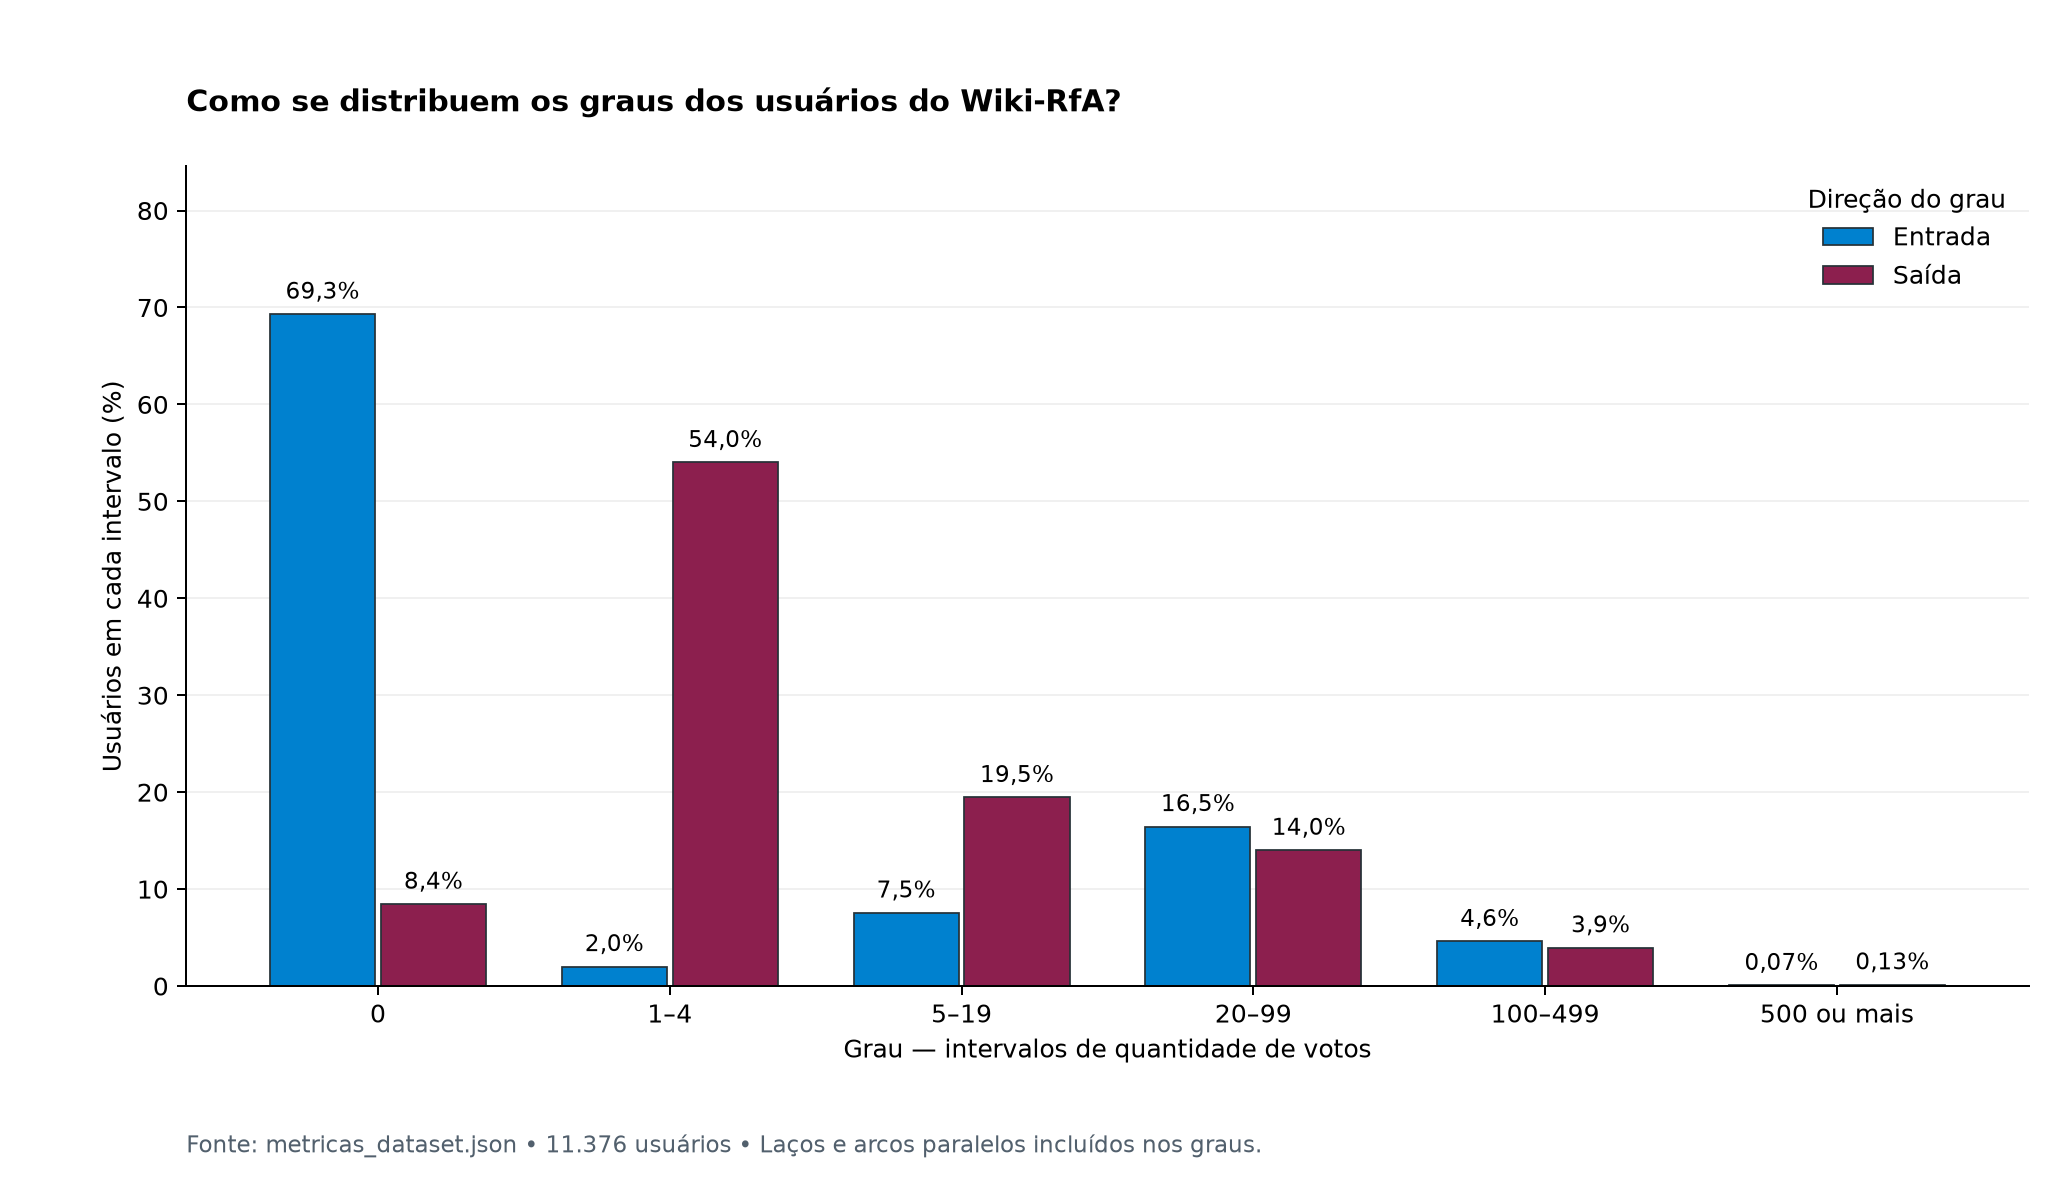

In [134]:
display(Image(filename=str(pasta_figuras / "andre_01_distribuicao_graus.png"), width=1000))


### A02 - Distribuição dos votos e pesos


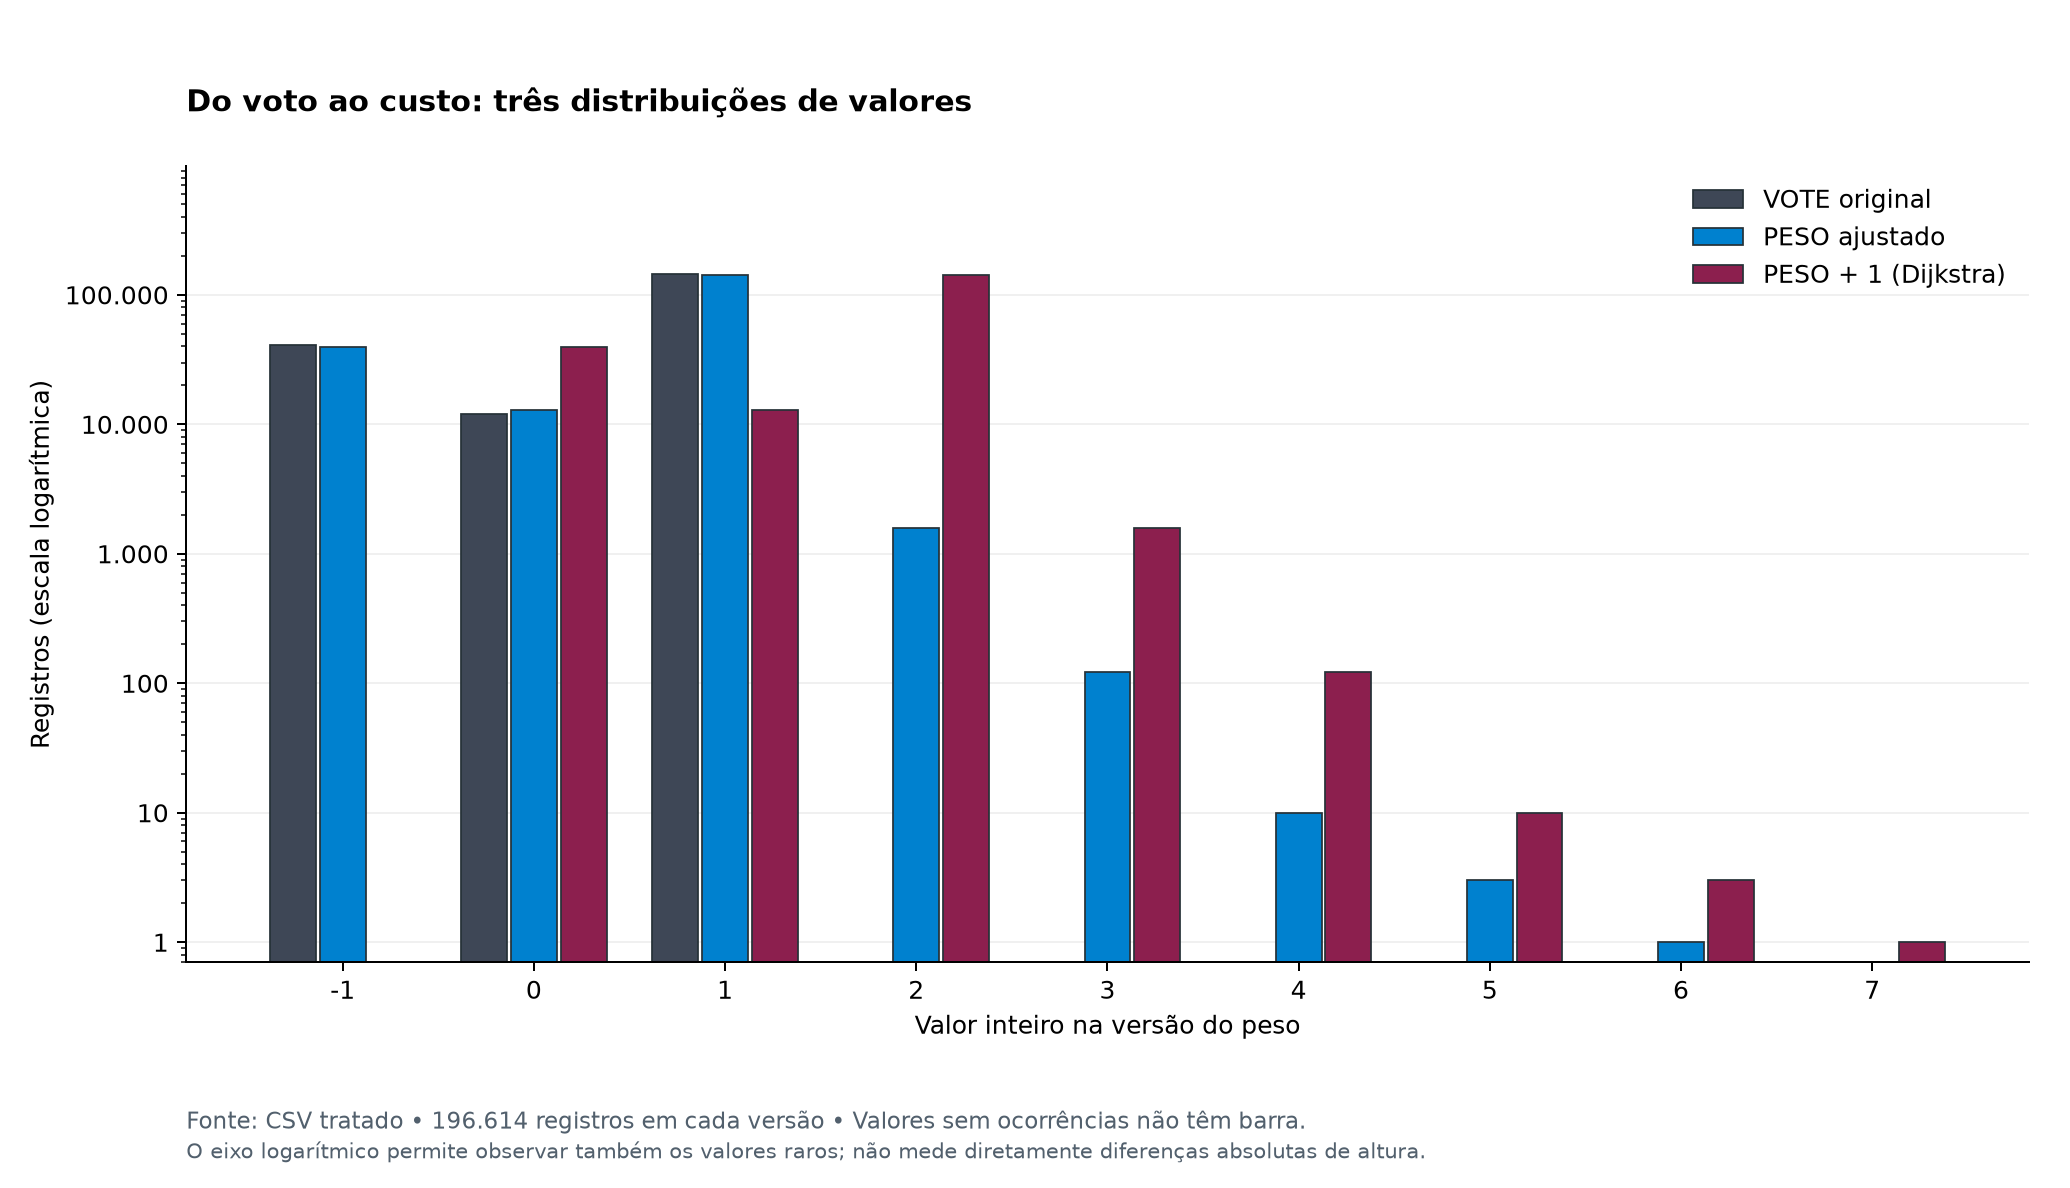

In [135]:
display(Image(filename=str(pasta_figuras / "andre_02_distribuicao_pesos.png"), width=1000))


### A03 - Tempos de DFS e Bellman-Ford


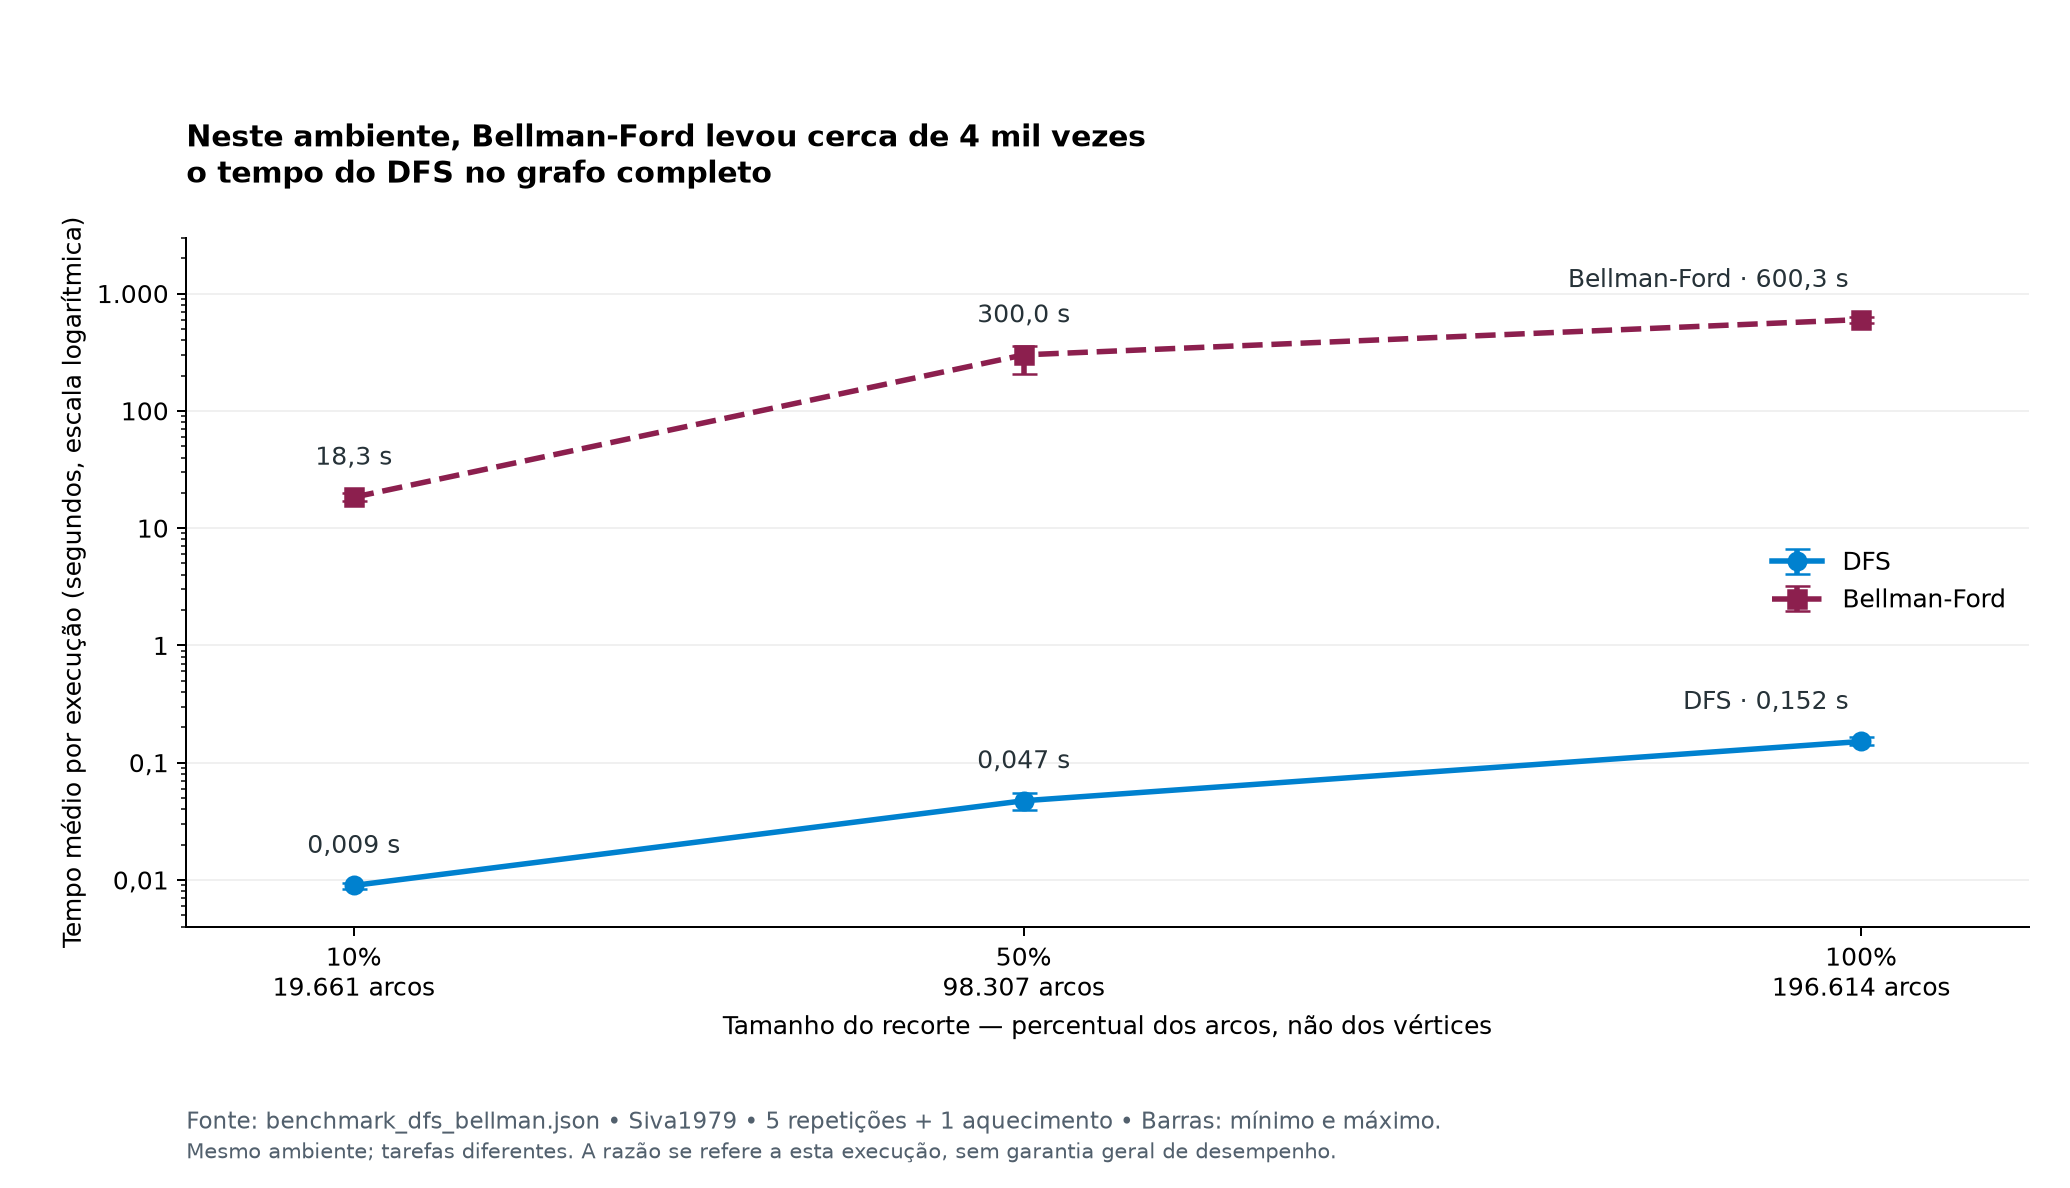

In [136]:
display(Image(filename=str(pasta_figuras / "andre_03_tempos_dfs_bellman.png"), width=1000))


### A04 - Atributos por resultado da candidatura


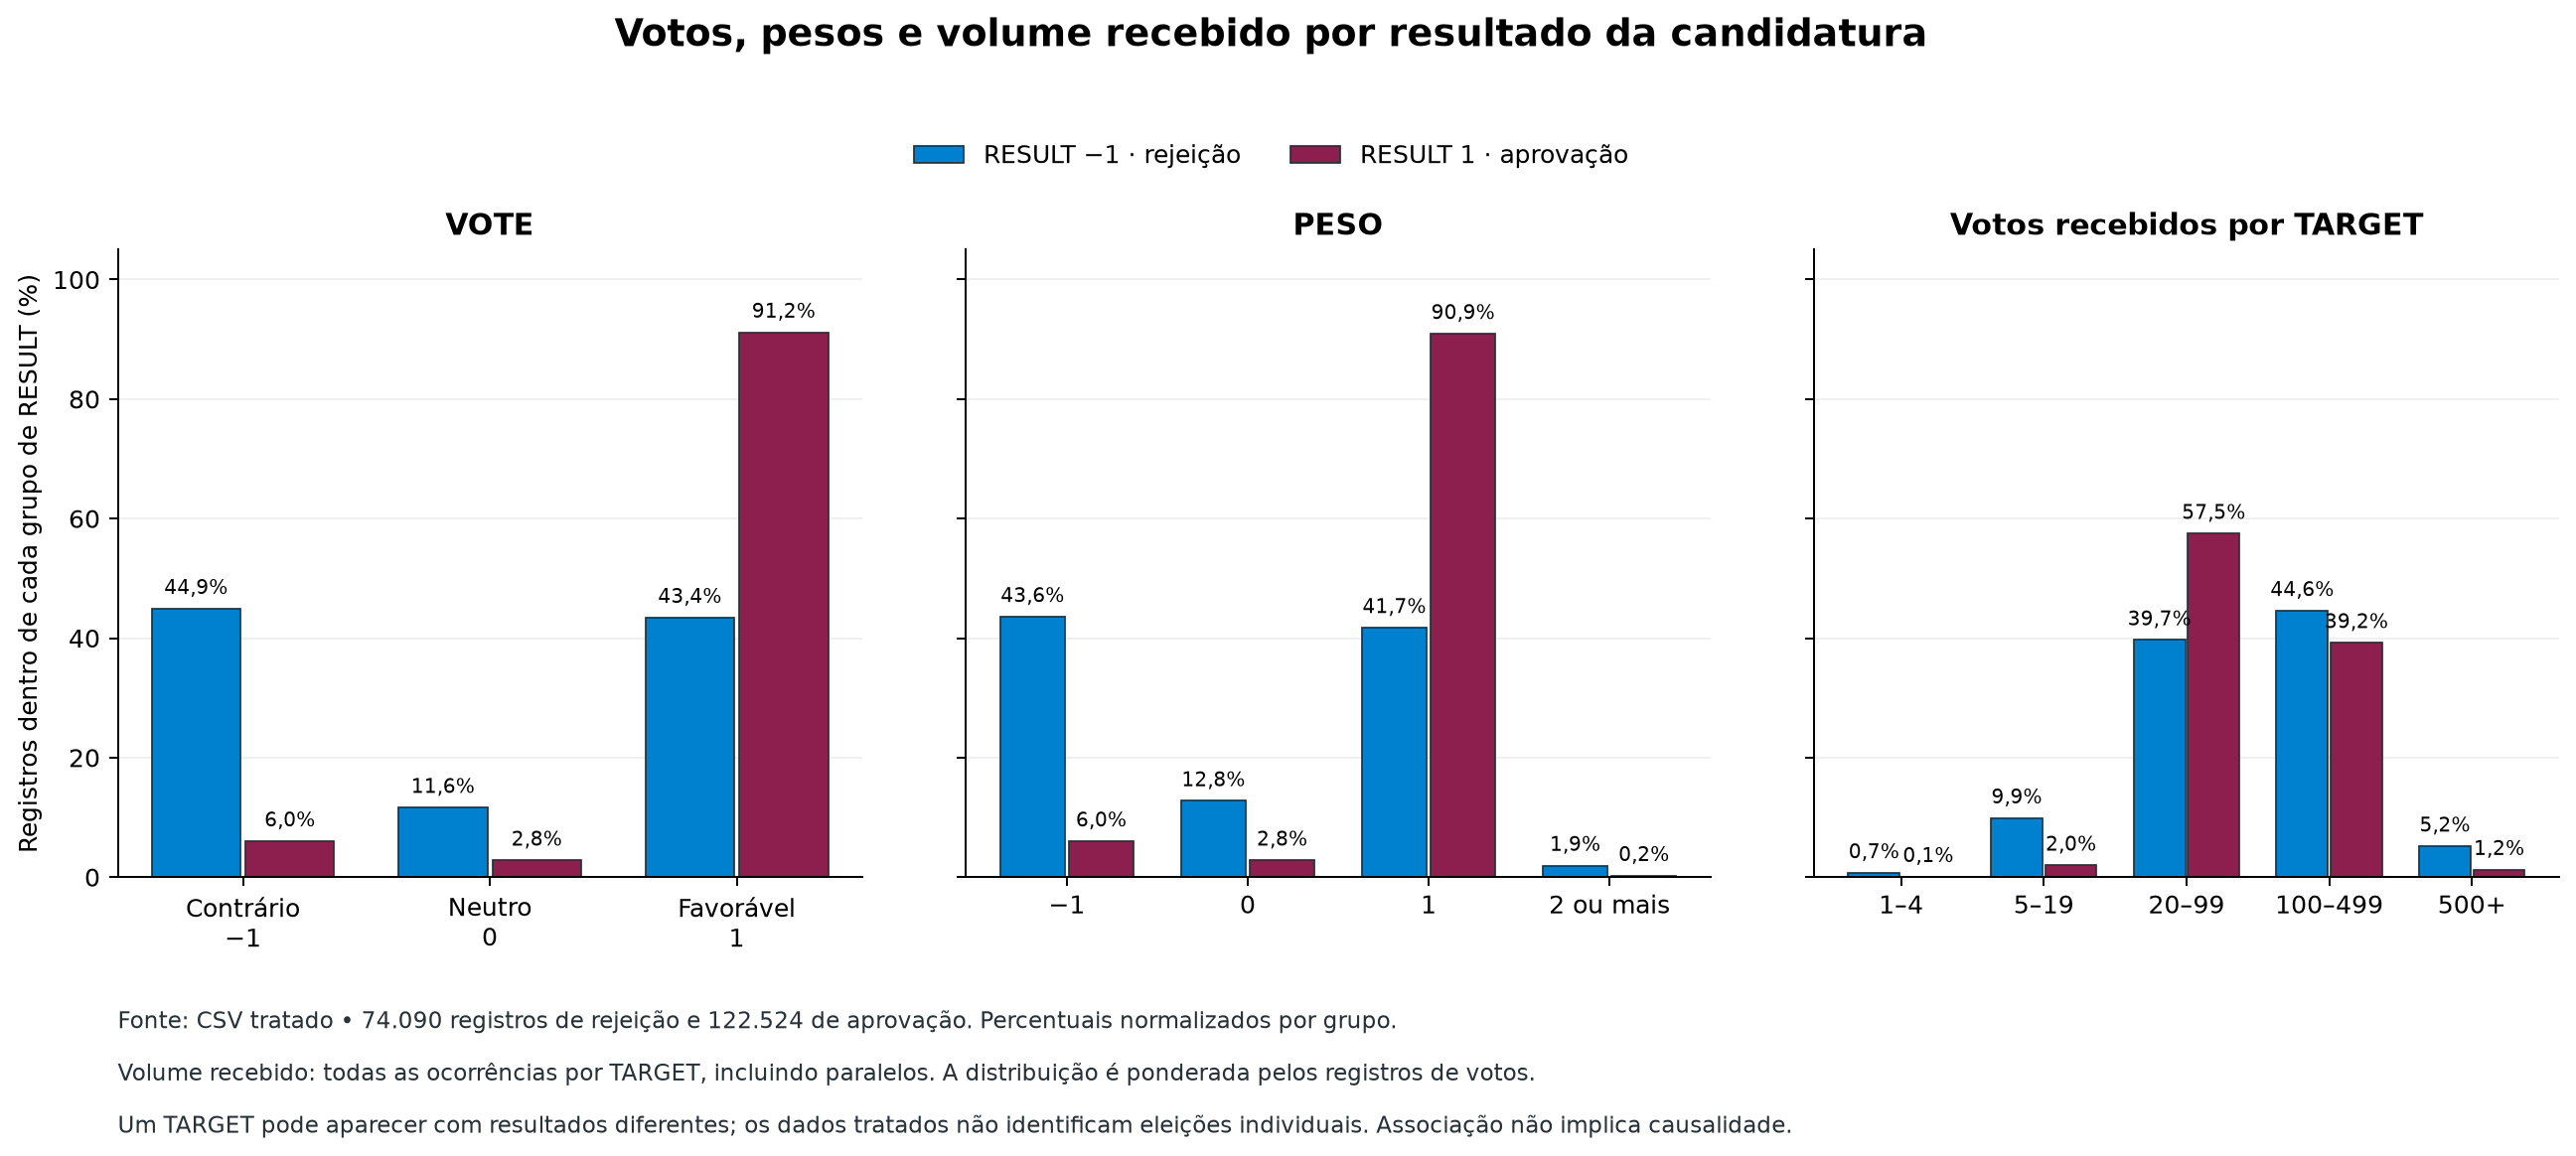

In [137]:
display(Image(filename=str(pasta_figuras / "andre_04_atributos_result.png"), width=1000))


### B01 - Votos sem origem por faixa


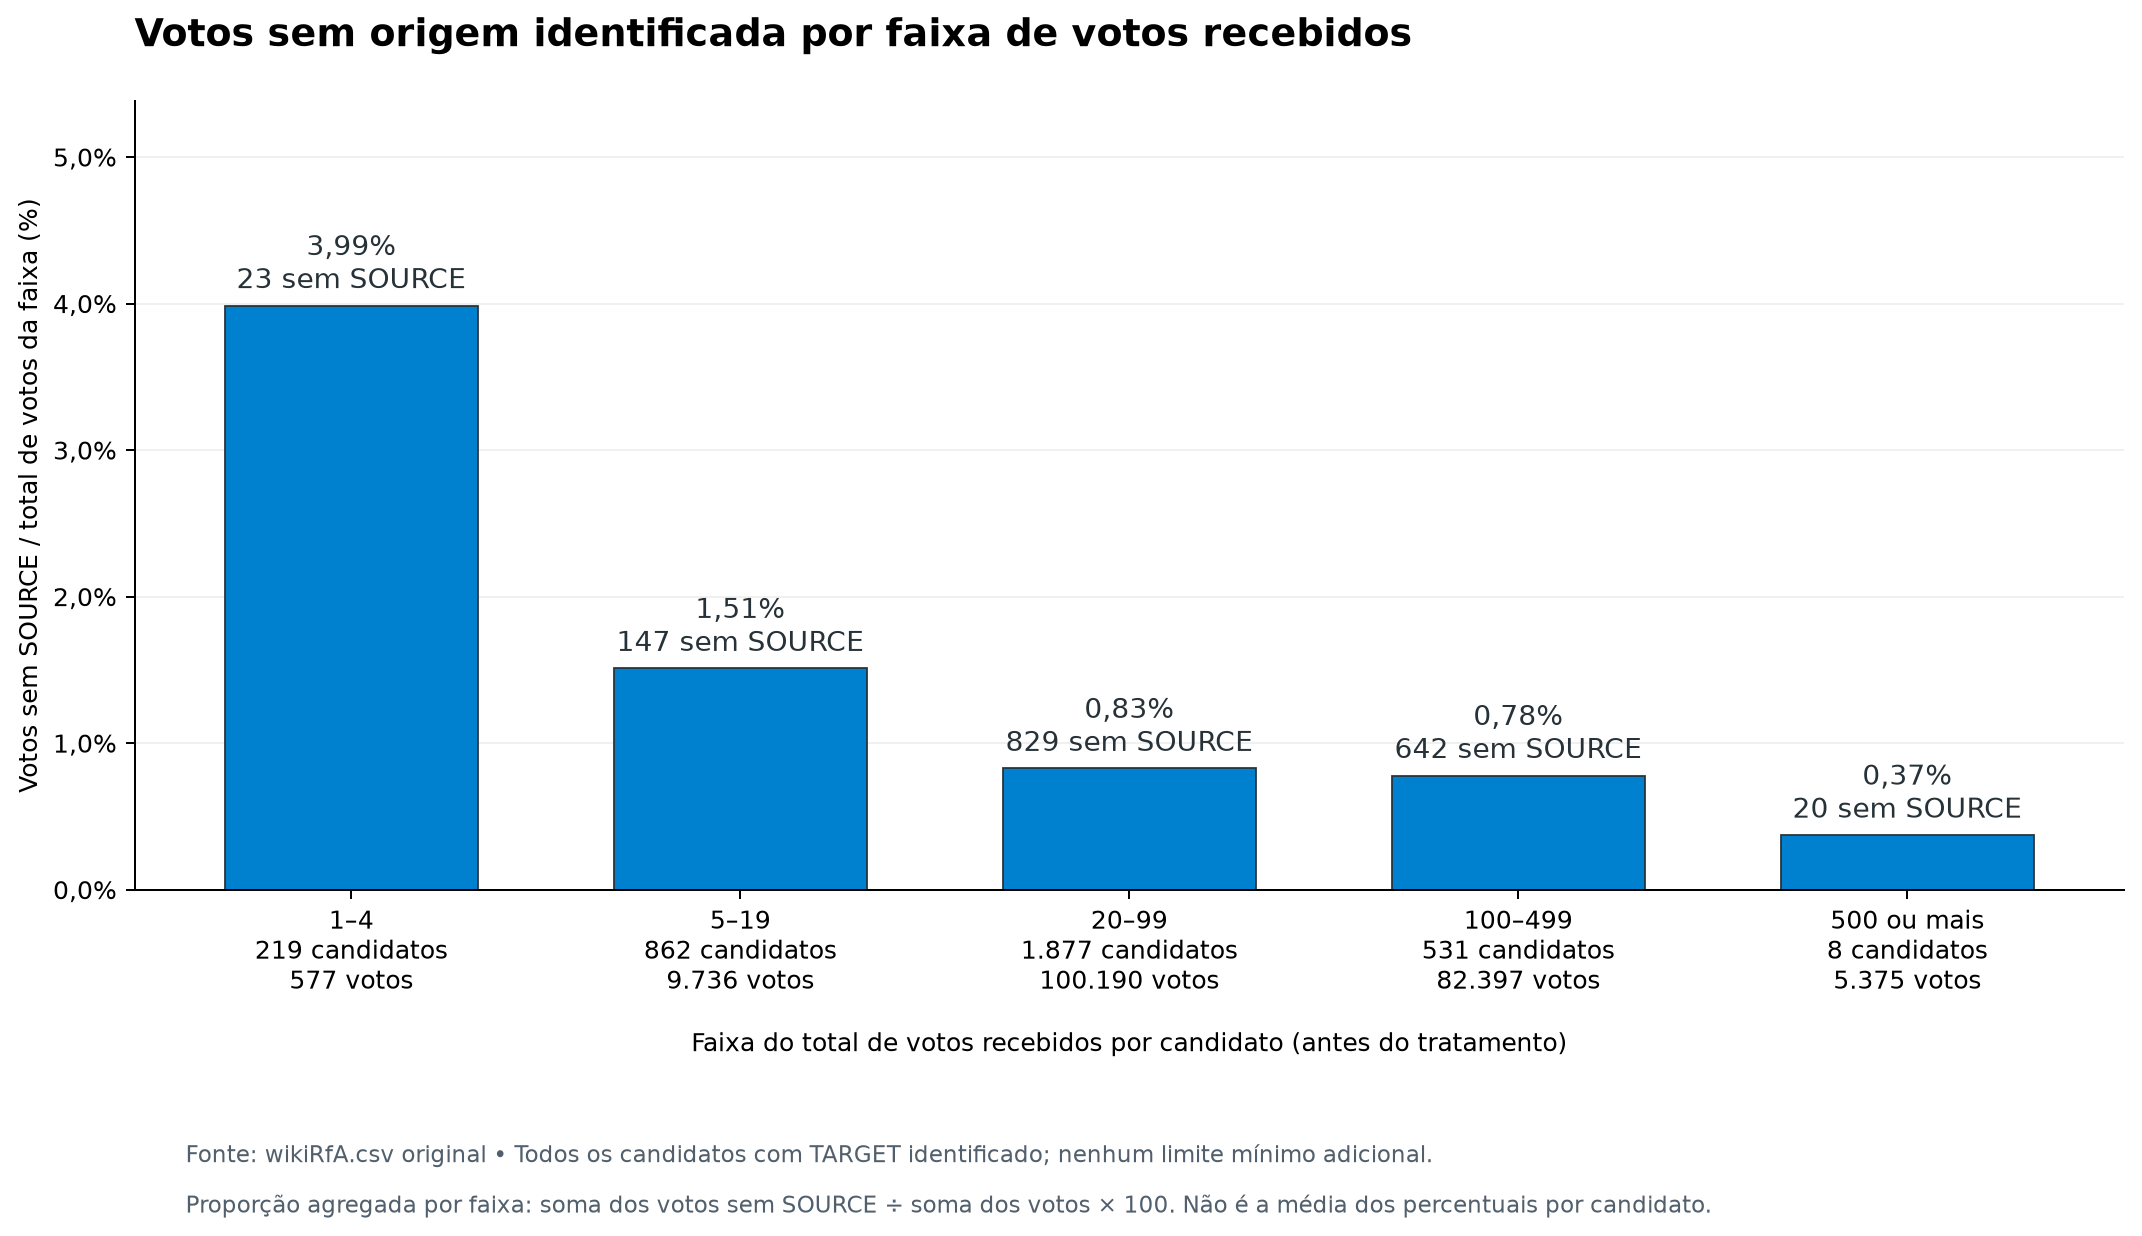

In [138]:
display(Image(filename=str(pasta_figuras / "brenda_01_faltantes_por_faixa.png"), width=1000))


### B02 - Tempos de BFS e Dijkstra


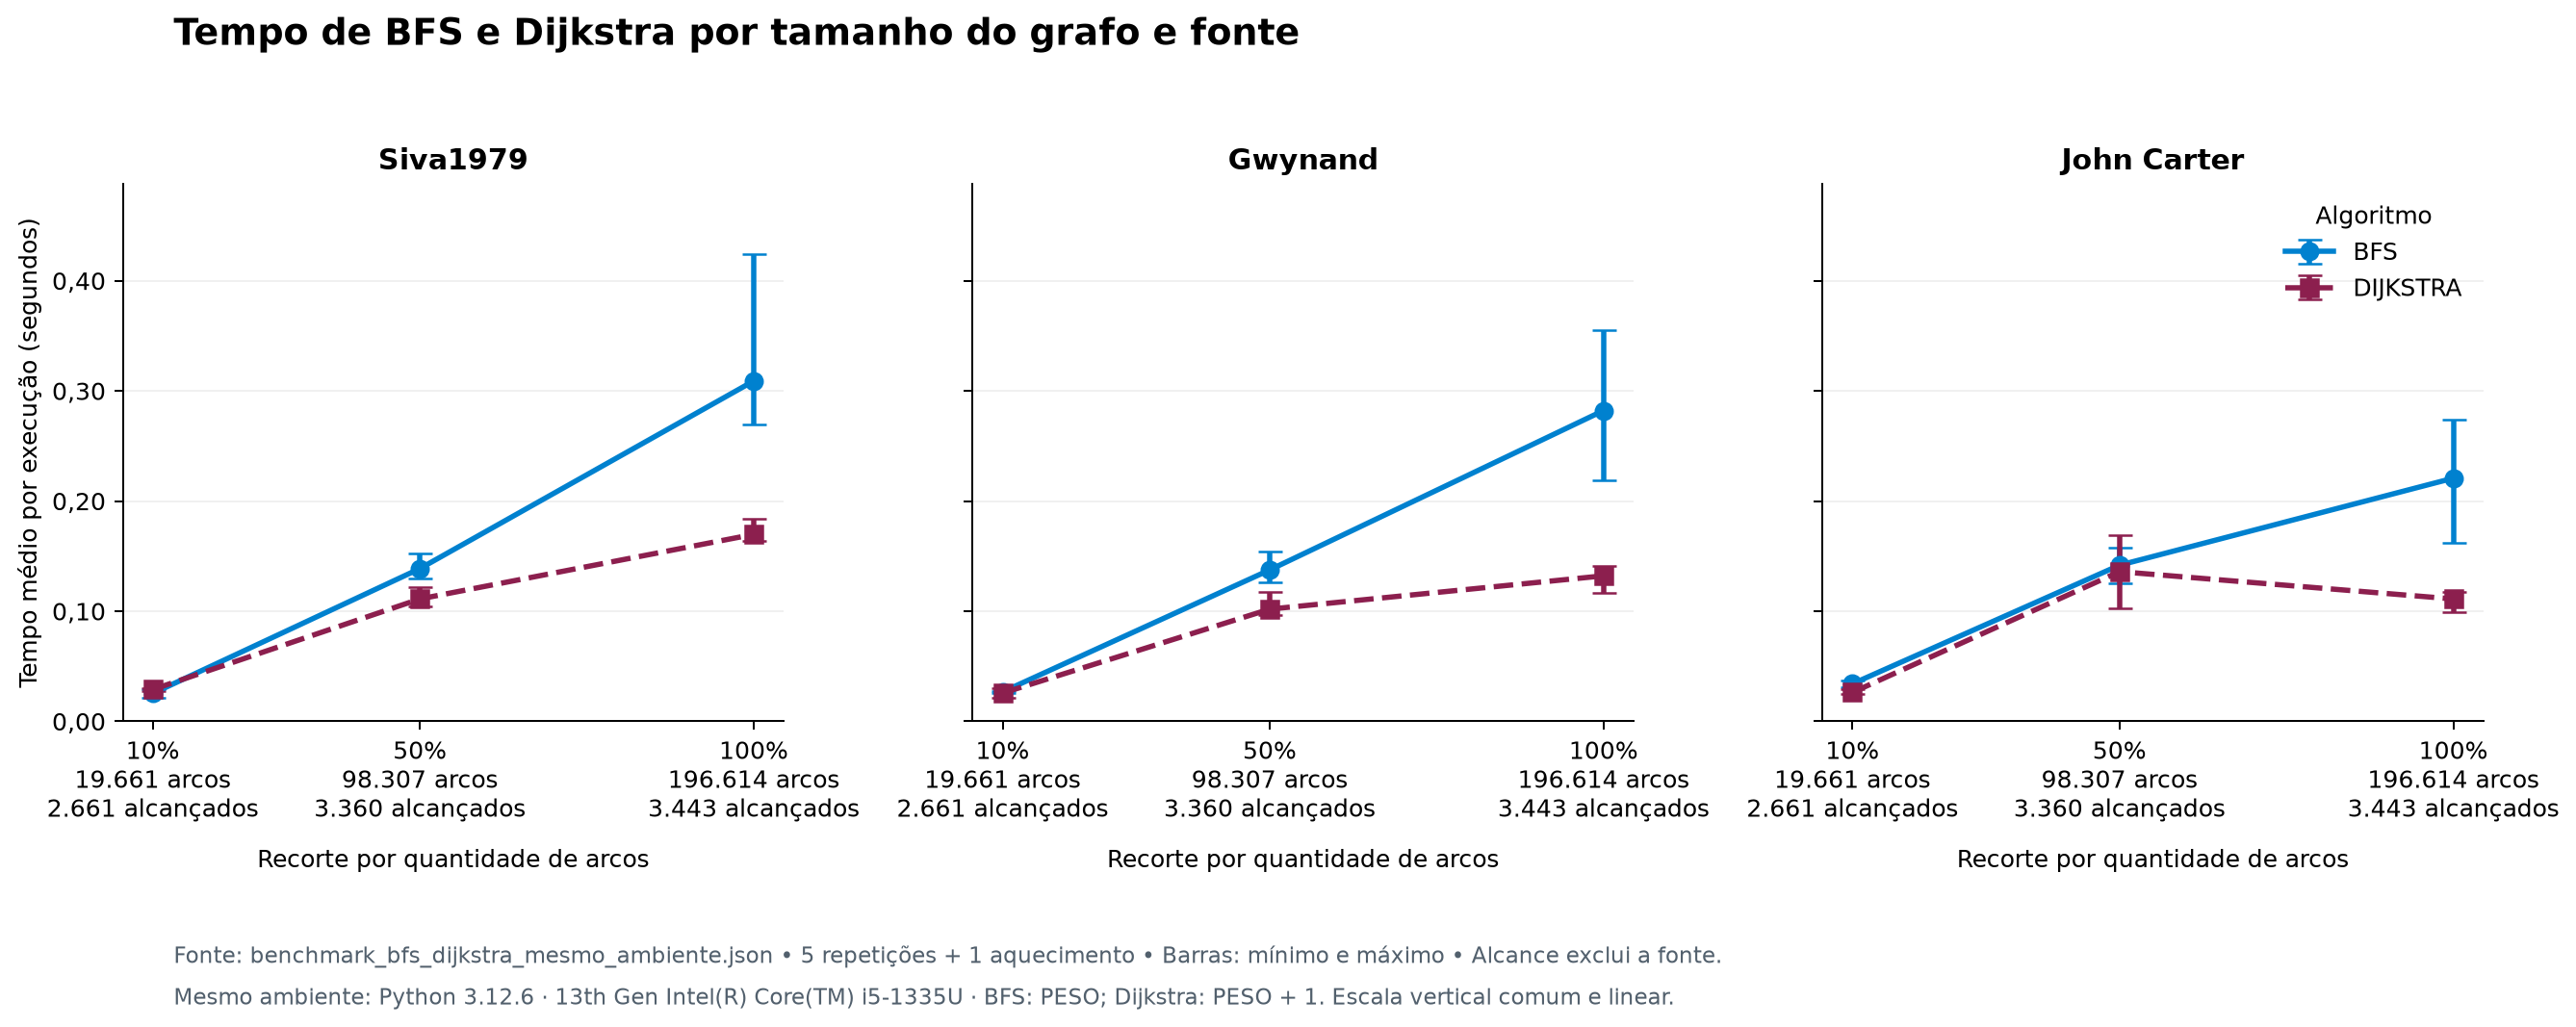

In [139]:
display(Image(filename=str(pasta_figuras / "brenda_02_tempos_bfs_dijkstra.png"), width=1000))


### B03 - Efeito da transformação dos pesos


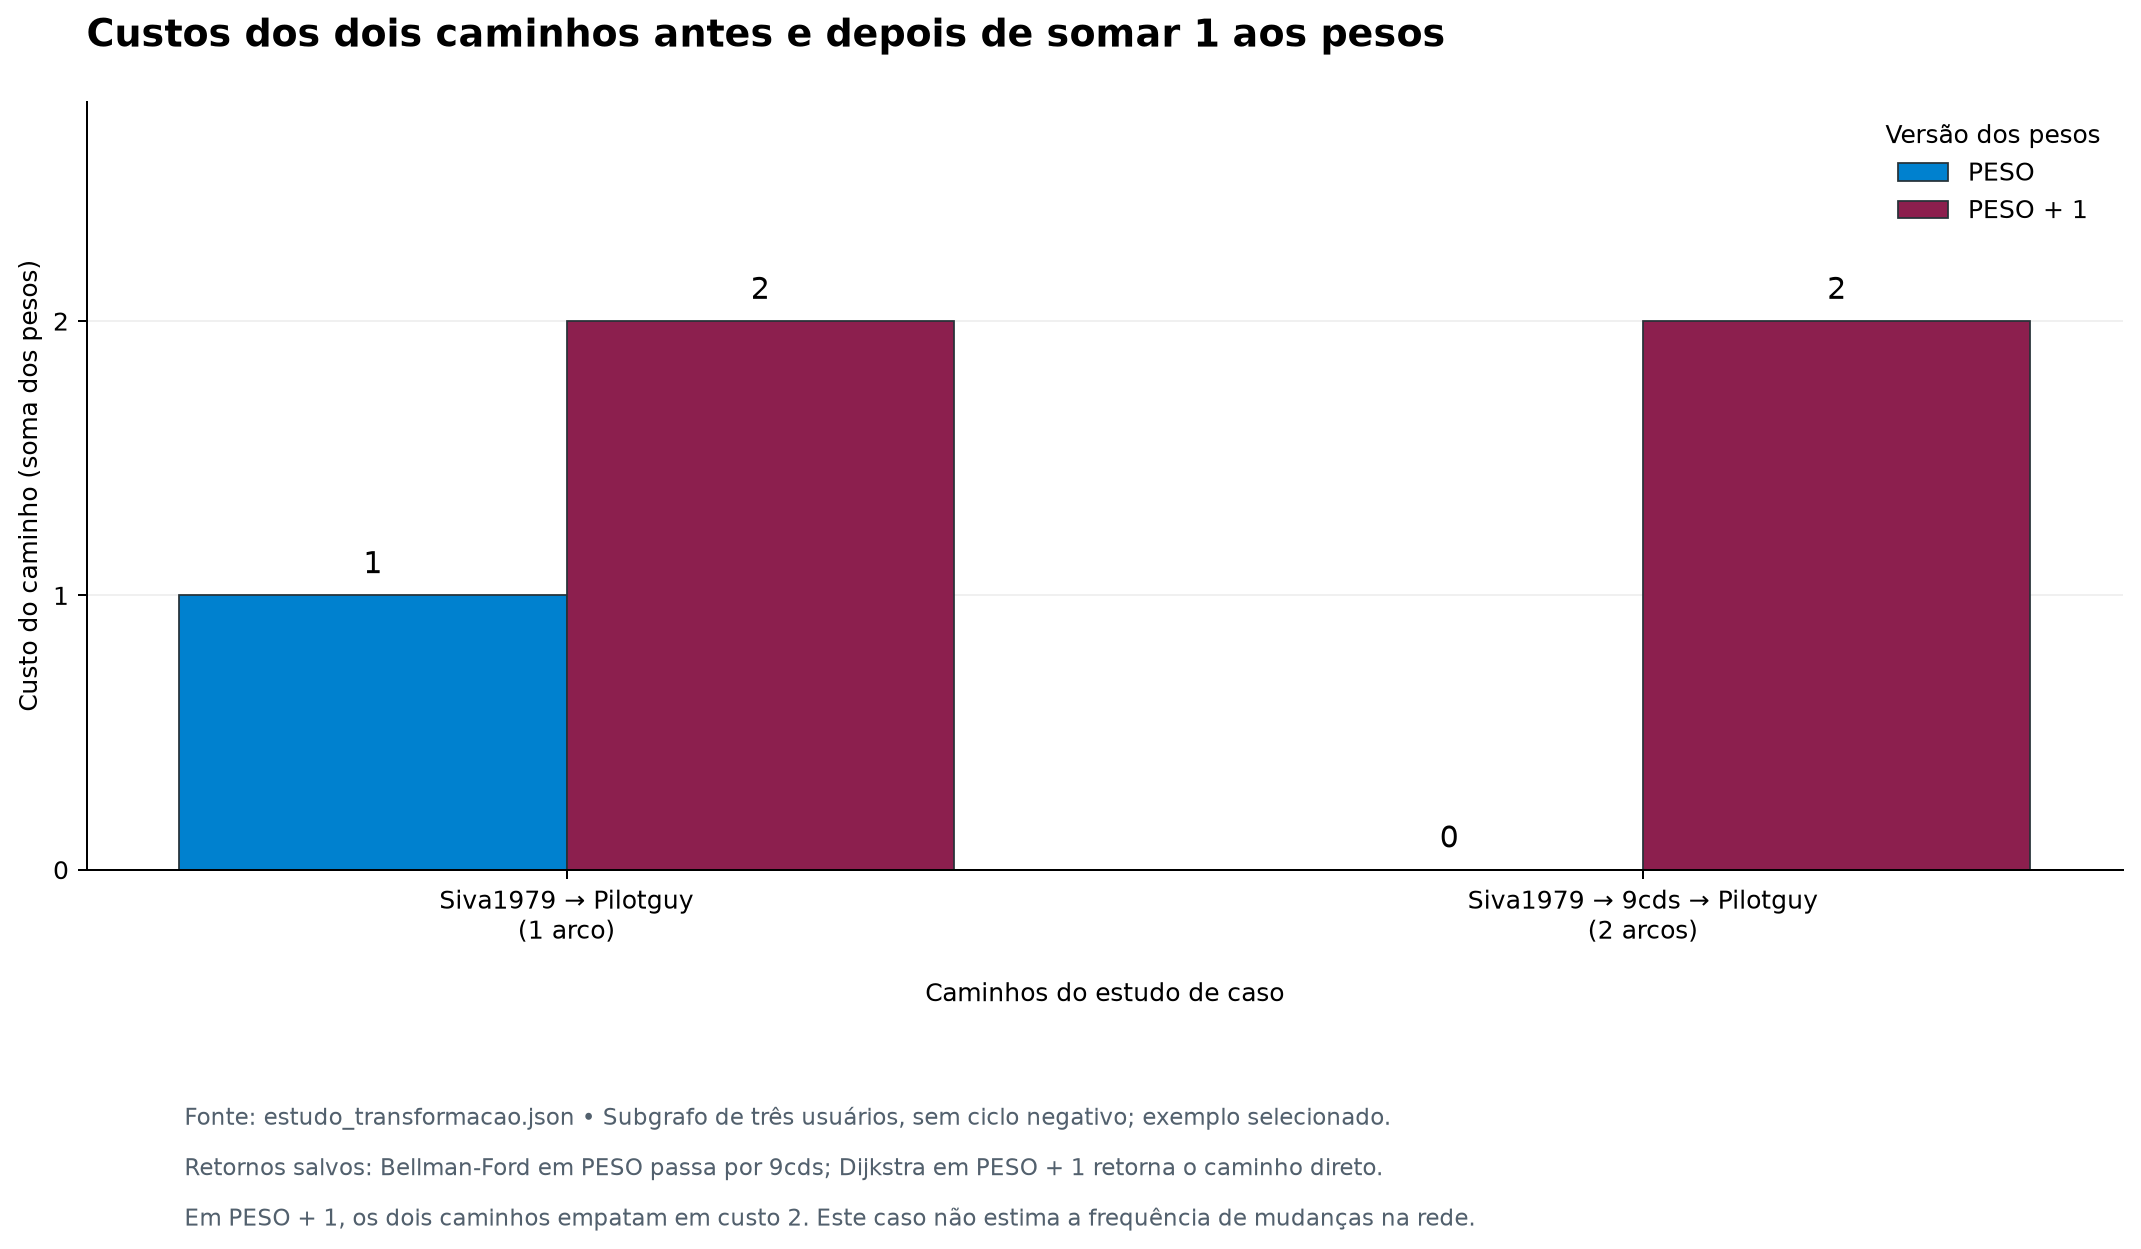

In [140]:
display(Image(filename=str(pasta_figuras / "brenda_03_efeito_transformacao.png"), width=1000))
